# Tiamat - previsão do número de citações de artigos científicos

**Autor:** Gustavo Junqueira Colas

**Orientador:** Prof. Dr. Daniel R. Cassar

**Instituição:** Ilum Escola de Ciência

**Data da coleta de dados:** 13 de novembro de 2026

<div style="text-align: justify; max-width: 96%">

_________________________________________________________________________________________________
**Observações importantes:**

Este notebook é autossuficiente, isto é, todo o código do projeto roda aqui dentro, de cima para baixo, sem depender de nenhum script externo. Os dados já coletados ficam na pasta `dados/` e as etapas mais demoradas guardam seus resultados em `saidas/`, de modo que uma segunda execução reaproveita o que já foi calculado (e leva poucos minutos, em vez de horas).

Vale ressaltar também que todo número citado no texto vem de uma saída executada neste notebook.
__________________________________________________________________________________________________
</div>

## 1. Resumo

<div style="text-align: justify; max-width: 96%">

O presente projeto teve como objetivo prever o impacto científico de artigos de inteligência artificial, medido pela contagem acumulada de citações, utilizando apenas informações conhecidas antes da publicação (título, resumo, autoria, afiliações, revista, tipo de publicação, tamanho da lista de referências e data). Para isso, artigos publicados entre 2018 e 2024 foram sorteados no PubMed e coletados por API, com uma cota igual por ano e semente fixa, e tiveram suas citações obtidas pela API da OpenAlex, com o casamento entre as duas bases feito apenas por identificador exato (DOI ou PMID). Após a limpeza, restaram 4835 artigos, descritos por 30 atributos e divididos em 3868 para treino e 967 para teste, com separação pelo ano. O alvo apresenta uma cauda longa acentuada (mediana de 26 citações, média de 60,25 e máximo de 5531 no treino), motivo pelo qual a modelagem foi feita sobre log(1 + citações).

Foram comparados um baseline (a mediana) e cinco pipelines otimizados pelo Optuna, com 100 trials e validação cruzada de 5 dobras: o Rigde, KNN, floresta aleatória, XGBoost e um stacking aninhado com meta-modelo Rigde. No conjunto de teste, o stacking obteve o menor RMSE na escala logarítmica (1,0059, contra 1,2516 da mediana), com MAE de 44,11 citações e correlação de Spearman de 0,602. No entanto, a comparação pareada por bootstrap mostrou que a vantagem do stacking sobre o Rigde (RMSE de 1,0083) não é distinguível do acaso, enquanto o &#119896;-NN e a floresta aleatória foram piores que o Rigde em todos os sorteios. A idade do artigo foi o atributo mais associado ao alvo (correlação de postos de 0,388), o que reforça que boa parte do que se consegue prever é o tempo que o artigo teve para ser citado. Os resultados indicam associação preditiva, e não causa.

</div>

## 2. Introdução

<div style="text-align: justify; max-width: 96%">

Primeiramente, é essencial entender o que é o aprendizado de máquina. Trata-se de uma área da inteligência artificial cujos métodos constroem um modelo a partir de exemplos, de forma que um algoritmo possa "aprender" os padrões dos dados de treinamento e, posteriormente, fazer inferências precisas sobre novos dados. Essa ideia, simples de enunciar, está hoje presente em uma variedade enorme de aplicações: filtros de spam, sistemas de recomendação, tradução automática e, de forma cada vez mais intensa, a saúde. 

Na medicina, modelos de aprendizado de máquina já são usados para interpretar exames de imagem, estimar o risco de pacientes e acelerar a descoberta de fármacos. Não apenas isso, como a própria produção científica sobre o tema cresceu rapidamente nos últimos anos - motivo pelo qual esse trabalho buscou debruçar-se sobre essa literatura emergente.

Dentro desse campo, o presente projeto trata de um problema de regressão supervisionada: supervisionado porque cada exemplo vem acompanhado da resposta correta, e de regressão porque essa resposta é um número (e não uma categoria). O número em questão é a contagem acumulada de citações - uma tentativa de medir o impacto científico que um artigo produziu.

A escolha da contagem de citações como medida advem do fato de que ela é a medida de impacto mais usada na prática (é o que alimenta índices como o h de Hirsch e o que, de fato, pesa em decisões de contratação, financiamento e curadoria), mesmo sendo também uma das mais criticadas. Como crítica, aponta-se que ela mede a atenção da comunidade, e não a qualidade ou a correção de um trabalho, além de ser sensível a fatores que pouco estão relacionados com o conteúdo de fato, como o tamanho da subárea, o idioma, a revista e o hábito de autocitação. Além disso, as citações se acumulam de forma muito desigual: artigos que já são citados tendem a atrair ainda mais citações, o que produz uma distribuição em que poucos artigos concentram boa parte do total.

Nesse contexto, existem dois motivos para tentar prever essa contagem a partir de informações disponíveis antes da publicação. O primeiro é principalmente prático: comitês editoriais, agências e grupos de pesquisa precisam priorizar a leitura dentro de um volume de literatura que cresce mais rápido do que a capacidade de acompanhá-lo, e um modelo que ordene razoavelmente bem os artigos pelo impacto esperado funcionaria como uma ferramenta de triagem (e não de julgamento!). O segundo serve como uma possível validação da crítica: se atributos puramente formais, sem nenhuma leitura do conteúdo, já predizem parte do impacto, isso revela algo desconfortável sobre o que a métrica realmente mede.

Considerando esses objetivos, o modelo utiliza apenas atributos conhecidos antes da publicação: o título, o resumo, a quantidade e a procedência dos autores, a revista, o tipo de publicação, o tamanho da lista de referências e a data. Essa restrição é o que separa uma previsão de uma descrição - afinal, é fácil explicar citações usando informações posteriores à publicação (como o número de downloads), mas isso provavelmente não serviria significativamente no momento em que a previsão seria realmente útil.


O notebook está organizado da seguinte forma: a seção 3 descreve a coleta dos dados pelas APIs do PubMed e da OpenAlex, a divisão entre treino e teste e a análise exploratória; a seção 4 apresenta os pipelines e a otimização de hiperparâmetros de cada algoritmo, comparando-os com o baseline; a seção 5 abre o conjunto de teste e compara todos os modelos, com intervalos de confiança e comparações pareadas por bootstrap; a seção 6 reúne as conclusões; a seção 7 trata do auxílio de ferramentas de inteligência artificial; e, finalmente, a seção 8 explicita as referências utilizadas. 


</div>

## 3. Coleta de dados

<div style="text-align: justify; max-width: 96%">

Antes de começar a coleta, a célula abaixo faz a configuração geral do notebook. Além das importações, ela fixa algumas coisas que valem destaque:

- `SEMENTE = 19` é usada por toda fonte de aleatoriedade do projeto (o sorteio da amostra, a divisão treino e teste, as dobras da validação cruzada, os algoritmos e o Optuna), o que torna a execução reproduzível;
- `N_DOBRAS` e `N_TRIALS` fixam o protocolo de avaliação, que é o mesmo para todos os modelos, enquanto `ANO_INICIAL` e `ANO_FINAL` delimitam a janela de publicação;
- as três pastas são criadas com `exist_ok=True`, de modo que a célula possa ser rodada de novo sem erro;
- as cores das figuras ficam definidas uma única vez, assim como a função `figura`, que salva e mostra cada gráfico (para não repetir `tight_layout` e `savefig` dezenas de vezes).

</div>

In [1]:

import json        # usei para guardar resultados em disco
import os          # caminhos e pastas
import time        # para medir quanto cada etapa demora
import warnings
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from scipy.stats import spearmanr

SEMENTE = 19          # toda fonte de aleatoriedade do projeto usa esta semente
N_DOBRAS = 5          # dobras da validação cruzada
N_TRIALS = 100        # trials do Optuna por algoritmo
ANO_INICIAL, ANO_FINAL = 2018, 2024

DADOS = "dados"
SAIDAS = "saidas"
FIGURAS = "figuras"
for pasta in (DADOS, SAIDAS, FIGURAS):
    os.makedirs(pasta, exist_ok=True)   # exist_ok evita erro ao rodar de novo

verdin = "#1D9E75"
roxin = "#534AB7"
laranjin = "#D85A30"
cinzin = "#444441"

plt.rcParams["figure.dpi"] = 110
warnings.filterwarnings("ignore", category=FutureWarning)


def figura(nome):
    """Salva a figura atual em figuras/ e a mostra no notebook."""
    plt.tight_layout()
    plt.savefig(os.path.join(FIGURAS, nome), dpi=150, bbox_inches="tight")
    plt.show()


print("Versões em uso")
for modulo in (np, pd, matplotlib):
    print(f"  {modulo.__name__:12s} {modulo.__version__}")

Versões em uso
  numpy        2.4.4
  pandas       3.0.3
  matplotlib   3.10.8


### 3.1. Web scraping e uso de APIs

<div style="text-align: justify; max-width: 96%">

Existem, basicamente, duas formas de obter dados de um site: o acesso por uma interface de programação (a API) e a raspagem do HTML (o chamado *web scraping*). Vale distingui-las com cuidado, pois a escolha entre uma e outra não é uma questão de gosto.

Um web scraper consiste em um programa que pede uma página HTML e extrai os dados do meio da marcação (seria como percorrer o que aparece quando se clica "Inspecionar" numa página, e coletar os dados). Como o HTML foi feito para apresentação, e não para troca de dados, é preciso localizar cada informação por meio de seletores, isto é, caminhos dentro da árvore do documento apoiados em nomes de tags, classes de CSS ou atributos. Feita a coleta de uma página, procura-se pelo seletor que fornece a página seguinte para coletar os dados novamente (até que se atinja um determinado critério de parada).

Um exemplo lúdico que serve para praticar é o site [Quotes to Scrape](https://quotes.toscrape.com/), feito justamente para isso. Nele, cada citação está em uma `div` de classe `quote`, com o texto em um `span` de classe `text`, o autor em um `small` de classe `author` e as etiquetas em links dentro de uma `div` de classe `tags`, o que deixa o programa didático e fácil de ser lido.

</div>

<div style="text-align: justify; max-width: 96%">

A célula abaixo faz a extração sobre um pouco de HTML com a mesma estrutura do Quotes to Scrape, embutido no próprio notebook para que ele rode sem depender da internet. O código está separado em três partes:

- `BeautifulSoup(html, "html.parser")` monta a árvore do documento;
- o laço percorre cada `div.quote` e, dentro dela, busca o texto, o autor e as etiquetas pelos seus seletores (`select` devolve todos os elementos que casam com um seletor de CSS, e `select_one` devolve apenas o primeiro, ou `None`);
- a última parte trata da paginação: o link para a próxima página está em `li.next a`, e uma raspagem real seguiria esse link, em laço, até ele sumir.

</div>

In [2]:
from bs4 import BeautifulSoup

# trecho com a mesma estrutura do Quotes to Scrape
# uma raspagem real depende de requests.get(url).text
html = """
<div class="quote">
  <span class="text">Exemplo de citacao numero um.</span>
  <small class="author">Autora Um</small>
  <div class="tags"><a class="tag" href="/tag/a/">a</a><a class="tag" href="/tag/b/">b</a></div>
</div>
<div class="quote">
  <span class="text">Exemplo de citacao numero dois.</span>
  <small class="author">Autor Dois</small>
  <div class="tags"><a class="tag" href="/tag/c/">c</a></div>
</div>
<ul class="pager"><li class="next"><a href="/page/2/">Next</a></li></ul>
"""

sopa = BeautifulSoup(html, "html.parser")

for bloco in sopa.select("div.quote"):
    texto = bloco.select_one("span.text").get_text(strip=True)
    autor = bloco.select_one("small.author").get_text(strip=True)
    etiquetas = [a.get_text(strip=True) for a in bloco.select("div.tags a.tag")]
    print(f"{autor:12s} | {texto} | etiquetas: {etiquetas}")

# a raspagem segue o link "Next" até não haver mais.
proxima = sopa.select_one("li.next a")
print("\npróxima página:", proxima["href"] if proxima else "não há")

Autora Um    | Exemplo de citacao numero um. | etiquetas: ['a', 'b']
Autor Dois   | Exemplo de citacao numero dois. | etiquetas: ['c']

próxima página: /page/2/


<div style="text-align: justify; max-width: 96%">

Repare no que a célula acima deixa visível. Cada campo depende de um seletor (`span.text`, `small.author`, `div.tags a.tag`) que descreve a aparência da página, e não o significado do dado. A paginação precisa ser descoberta e percorrida à mão (ou sob a orientação de agentes de IA), seguindo o link `Next` até que se atinja o critério de parada. Essa repetição leva a um número elevado de requisições que frequentemente são confundidos com ataques ao site (e, mesmo quando não são, há sites que buscam proteger suas informações contra esse tipo de coleta).

Por isso há as APIs: uma API é um canal que o próprio provedor publica para ser consumido por programas sob documentação e regras bem estabelecidas. Nesse cenário, o cliente faz uma requisição HTTP a um endereço documentado, com parâmetros previstos, e recebe de volta dados estruturados (em geral, em JSON ou XML). Perceba que, nesse caso, os campos têm nome e tipo estáveis, o provedor documenta os limites de uso e uma mudança no visual do site não impede a coleta adequada, já que a API não é o site.


Portanto, **o presente trabalho não usa web scraping**. Tanto o PubMed quanto a OpenAlex publicam APIs oficiais, documentadas e destinadas exatamente a este uso, de modo que raspar o HTML dessas bases seria mais frágil, mais lento, mais pesado para os servidores delas e, acima de tudo, desnecessário. Esta seção está no relatório porque o tema fez parte do desenvolvimento inicial do projeto e porque entender a diferença é o que permite afirmar, com fundamento, que aqui ela não se aplica.

</div>

### 3.2. Utilizando PubMed e OpenAlex

<div style="text-align: justify; max-width: 96%">

A primeira fonte é o PubMed, acessado pelas E-utilities do NCBI. O termo de busca reúne as expressões *machine learning*, *deep learning*, *artificial intelligence* e *neural network* no título ou no resumo, restritas a artigos de periódico em inglês, com resumo disponível e publicados entre 2018 e 2024.

Para a amostragem, o caminho mais simples seria pedir os primeiros cinco mil resultados na ordem em que o PubMed os devolve - mas isso seria um erro! Já existe uma ordenação por relevância, relevância que incorpora sinais de visibilidade, de modo que a amostra ficaria enviesada exatamente na direção do que o modelo tenta prever. Em vez disso, os identificadores (PMIDs) são enumerados mês a mês, em 84 janelas ao todo, e sorteia-se uma cota igual por ano.

A segunda fonte é a OpenAlex, de onde vêm as citações, uma vez que a API do PubMed não as fornece. Para certificar que os artigos coletados sejam <b>exatamente</b> os mesmos, entre as duas bases é feito apenas por DOI ou PMID - utilizar títulos, por exemplo, poderia introduzir "ruídos" (um artigo é confundido com outro, de forma que se colete o número de citações incompatíveis) evitáveis.

Por fim, a data da consulta fica gravada em todas as linhas, já que as citações se acumulam com o tempo e toda contagem deste trabalho é uma fotografia de uma data específica. Neste caso, a data da coleta, carimbada nas colunas `data_coleta` e `data_coleta_citacoes`, foi 13 de novembro de 2026, tanto para o PubMed quanto para a OpenAlex.

</div>

<div style="text-align: justify; max-width: 96%">

A célula abaixo apenas define parâmetros, sem executar nada de caro. A variável `RECOLETAR` é a chave que controla toda a seção: em `False`, as células seguintes reaproveitam os CSVs já coletados; em `True`, refazem a coleta do zero. Já `QUERY_PUBMED` é o termo de busca, escrito na sintaxe de campos do PubMed: `[tiab]` procura no título e no resumo, `[lang]` filtra o idioma e `[pt]` o tipo de publicação (perceba que a janela de datas não está aqui, pois ela é montada mês a mês mais adiante).
</div>

In [ ]:
RECOLETAR = False          # True força recoletar tudo do zero

CAMINHO_RAW = os.path.join(DADOS, "pubmed_raw.csv")
CAMINHO_CIT = os.path.join(DADOS, "pubmed_citacoes.csv")

QUERY_PUBMED = (
    '("machine learning"[tiab] OR "deep learning"[tiab] OR '
    '"artificial intelligence"[tiab] OR "neural network"[tiab] OR '
    '"neural networks"[tiab]) '
    "AND hasabstract AND english[lang] AND journal article[pt]"
)

# print("Parâmetros definidos.")

Parâmetros definidos.


<div style="text-align: justify; max-width: 96%">

Agora, duas peças de infraestrutura que as duas APIs compartilham:

 - **A classe `Limitador`** $\to$ guarda o instante da última requisição (com `time.monotonic()`) e espera exatamente o que falta para completar o intervalo mínimo entre duas requisições. Isso é melhor que um `sleep` fixo, pois aproveita o tempo já gasto processando a resposta anterior: assim, usa-se toda a taxa permitida sem nunca ultrapassar o limite.

 - **A função `requisicao`** $\to$ envolve o `requests` em tentativas repetidas, com espera crescente. O ponto importante é a classificação dos erros: o código 429 (excesso de requisições) e os códigos 5xx (erros do servidor) são tratados como temporários e merecem uma nova tentativa; qualquer outro código levanta exceção na hora, já que repetir não ajudaria. A espera dobra a cada tentativa, de 2 a 32 segundos, e o número de tentativas é limitado a cinco.

</div>

In [ ]:
import hashlib
import random
import xml.etree.ElementTree as ET

import requests


class Limitador:
    def __init__(self, req_por_segundo):
        self.intervalo = 1.0 / req_por_segundo
        self.ultimo = 0.0

    def espera(self):
        restante = self.intervalo - (time.monotonic() - self.ultimo)
        if restante > 0:
            time.sleep(restante)
        self.ultimo = time.monotonic()


def requisicao(url, params, limitador, tentativas=5, metodo="get"):
    # erros 429 e 5xx = temporários, recua exponencialmente 
    for tentativa in range(1, tentativas + 1):
        limitador.espera()
        try:
            if metodo == "post":
                resposta = requests.post(url, data=params, timeout=120)
            else:
                resposta = requests.get(url, params=params, timeout=120)
            if resposta.status_code == 200:
                return resposta
            if resposta.status_code not in (429, 500, 502, 503, 504):
                resposta.raise_for_status()
            motivo = f"HTTP {resposta.status_code}"
        except requests.RequestException as erro:
            motivo = str(erro)
        espera = 2 ** tentativa
        print(f"  aviso: {motivo}. Nova tentativa em {espera}s [{tentativa}/{tentativas}]")
        time.sleep(espera)
    raise RuntimeError(f"Requisição falhou após {tentativas} tentativas: {url}")


# print("Limitador e requisicao definidos")

Limitador e requisicao definidos


<div style="text-align: justify; max-width: 96%">

A extração dos campos de cada artigo a partir do XML do PubMed é feita por quatro funções auxiliares, sendo importante denotar o que cada uma resolve:

- `texto` usa `itertext()` em vez de `.text`, porque o PubMed insere marcação dentro dos campos (um título com itálico vira vários nós, e `.text` pegaria só o primeiro pedaço). O `" ".join(...split())` normaliza os espaços;

- `extrai_resumo` junta as seções do resumo preservando os rótulos, já que resumos estruturados vêm partidos em `BACKGROUND`, `METHODS` e assim por diante;

- `extrai_datas` trata um caso chato: alguns registros não têm o campo `Year` e trazem só `MedlineDate`, uma string como `"2019 Jan-Feb"`, de onde o ano é recortado;

- `extrai_autores` lida com autores coletivos (que têm `CollectiveName` em vez de sobrenome) e infere o país pelo último campo da afiliação. Essa inferência é heurística, e os filtros de 40 caracteres e de arroba descartam os casos em que o último campo é um endereço de e-mail.

Por fim, `extrai_artigo` usa as quatro para montar uma linha da tabela por artigo.

</div>

In [ ]:
BASE_NCBI = "https://eutils.ncbi.nlm.nih.gov/entrez/eutils"

COLUNAS_PUBMED = [
    "pmid", "doi", "titulo", "resumo", "revista", "revista_abrev", "issn",
    "ano_publicacao", "mes_publicacao", "data_eletronica",
    "n_autores", "autores", "n_afiliacoes", "afiliacoes", "paises",
    "n_mesh", "mesh_terms", "n_keywords", "keywords",
    "tipos_publicacao", "idioma", "n_financiamentos", "financiadores",
    "paginas", "n_referencias_pubmed", "data_coleta",
]


def texto(elemento):
    if elemento is None:
        return ""
    return " ".join("".join(elemento.itertext()).split())


def extrai_resumo(artigo):
    partes = []
    for trecho in artigo.findall(".//Abstract/AbstractText"):
        conteudo = texto(trecho)
        if conteudo:
            rotulo = trecho.get("Label")
            partes.append(f"{rotulo}: {conteudo}" if rotulo else conteudo)
    return " ".join(partes)


def extrai_datas(artigo):
    ano = mes = ""
    pub_date = artigo.find(".//Journal/JournalIssue/PubDate")
    if pub_date is not None:
        ano, mes = texto(pub_date.find("Year")), texto(pub_date.find("Month"))
        if not ano:
            # Alguns registros trazem só MedlineDate, por exemplo "2019 Jan-Feb"
            medline = texto(pub_date.find("MedlineDate"))
            if medline:
                ano, mes = medline[:4], medline[5:].strip()

    eletronica = ""
    data_art = artigo.find(".//Article/ArticleDate")
    if data_art is not None:
        partes = [texto(data_art.find(c)) for c in ("Year", "Month", "Day")]
        if all(partes):
            eletronica = "-".join(p.zfill(2) if i else p for i, p in enumerate(partes))
    return {"ano": ano, "mes": mes, "eletronica": eletronica}


def extrai_autores(artigo):
    nomes, afiliacoes = [], []
    for autor in artigo.findall(".//AuthorList/Author"):
        sobrenome = texto(autor.find("LastName"))
        nome = texto(autor.find("ForeName"))
        coletivo = texto(autor.find("CollectiveName"))
        if sobrenome or nome:
            nomes.append(" ".join(p for p in (nome, sobrenome) if p))
        elif coletivo:
            nomes.append(coletivo)
        for af in autor.findall(".//AffiliationInfo/Affiliation"):
            valor = texto(af)
            if valor and valor not in afiliacoes:
                afiliacoes.append(valor)
        
    paises = []
    for af in afiliacoes:
        ultimo = af.rstrip(".").split(",")[-1].strip()
        if ultimo and "@" not in ultimo and len(ultimo) <= 40 and ultimo not in paises:
            paises.append(ultimo)
            # geralmente o país é o último campo da afiliação
    return {"nomes": nomes, "afiliacoes": afiliacoes, "paises": paises}


def extrai_artigo(artigo, data_coleta):
    pmid = texto(artigo.find(".//MedlineCitation/PMID"))
    if not pmid:
        return None

    doi = ""
    for ident in artigo.findall(".//ArticleIdList/ArticleId"):
        if ident.get("IdType") == "doi":
            doi = texto(ident).lower()
            break

    datas, autoria = extrai_datas(artigo), extrai_autores(artigo)
    mesh = [texto(d) for d in artigo.findall(".//MeshHeadingList/MeshHeading/DescriptorName")]
    keywords = [texto(k) for k in artigo.findall(".//KeywordList/Keyword")]
    tipos = [texto(t) for t in artigo.findall(".//PublicationTypeList/PublicationType")]
    financiadores = list(dict.fromkeys(
        f for f in (texto(a) for a in artigo.findall(".//GrantList/Grant/Agency")) if f))

    return {
        "pmid": pmid, "doi": doi,
        "titulo": texto(artigo.find(".//Article/ArticleTitle")),
        "resumo": extrai_resumo(artigo),
        "revista": texto(artigo.find(".//Journal/Title")),
        "revista_abrev": texto(artigo.find(".//Journal/ISOAbbreviation")),
        "issn": texto(artigo.find(".//Journal/ISSN")),
        "ano_publicacao": datas["ano"], "mes_publicacao": datas["mes"],
        "data_eletronica": datas["eletronica"],
        "n_autores": len(autoria["nomes"]), "autores": "; ".join(autoria["nomes"]),
        "n_afiliacoes": len(autoria["afiliacoes"]),
        "afiliacoes": " | ".join(autoria["afiliacoes"]),
        "paises": "; ".join(autoria["paises"]),
        "n_mesh": len(mesh), "mesh_terms": "; ".join(mesh),
        "n_keywords": len(keywords), "keywords": "; ".join(keywords),
        "tipos_publicacao": "; ".join(tipos),
        "idioma": texto(artigo.find(".//Article/Language")),
        "n_financiamentos": len(financiadores),
        "financiadores": "; ".join(financiadores),
        "paginas": texto(artigo.find(".//Pagination/MedlinePgn")),
        "n_referencias_pubmed": len(artigo.findall(".//ReferenceList/Reference")),
        "data_coleta": data_coleta,
    }


# print("Extração do XML do PubMed definida")

Extração do XML do PubMed definida


<div style="text-align: justify; max-width: 96%">

Também são utilizadas as seguintes funções para contornar o problema da ordem supracitado:

- `fim_do_mes` calcula o último dia de cada mês indo ao primeiro dia do mês seguinte e voltando um dia, o que trata anos bissextos sem precisar de tabela;
- `pmids_do_mes` faz uma busca (ESearch) com a janela de datas daquele mês e `retmax` igual a dez mil, que é o teto da ferramenta;
- `amostra_mensal` caso a lista já tenha sido coletada, ela é reaproveitada, o que garante que a amostra não mude entre execuções. No contrário, percorre as 84 janelas, embaralha os identificadores de cada ano e toma uma cota igual por ano (o bloco final só completa a amostra caso algum ano tenha menos artigos que a cota). 
- `coleta_pubmed` busca a amostra, baixa os artigos em lotes de 200 e grava o XML bruto de cada lote em disco antes de processá-lo (os lotes são enviados por POST porque uma URL com duzentos identificadores estouraria o limite de tamanho de um GET)

</div>

In [ ]:
def fim_do_mes(ano, mes):
    import datetime as dt
    if mes == 12:
        return 31
    return (dt.date(ano, mes + 1, 1) - dt.timedelta(days=1)).day


def pmids_do_mes(query, ano, mes, limitador, extras):
    inicio = f"{ano}/{mes:02d}/01"
    fim = f"{ano}/{mes:02d}/{fim_do_mes(ano, mes):02d}"
    params = {"db": "pubmed", "retmax": "10000", "retmode": "xml",
              "term": f'{query} AND ("{inicio}"[pdat] : "{fim}"[pdat])', **extras}
    resposta = requisicao(f"{BASE_NCBI}/esearch.fcgi", params, limitador)
    return [texto(i) for i in ET.fromstring(resposta.content).findall(".//IdList/Id")]


def amostra_mensal(query, alvo, limitador, extras, caminho_lista):
    """Enumera os PMIDs mês a mês e sorteia uma cota igual por ano."""
    if os.path.exists(caminho_lista):
        with open(caminho_lista, encoding="utf-8") as arquivo:
            lista = json.load(arquivo)
        print(f"Lista de PMIDs reaproveitada: {len(lista)} identificadores")
        return lista

    anos = list(range(ANO_INICIAL, ANO_FINAL + 1))
    por_ano = {ano: [] for ano in anos}

    print(f"Enumerando os PMIDs mês a mês ({len(anos) * 12} janelas)...")
    for ano in anos:
        for mes in range(1, 13):
            ids = pmids_do_mes(query, ano, mes, limitador, extras)
            por_ano[ano].extend(ids)
            print(f"  {ano}-{mes:02d}: {len(ids)} artigos")

    sorteador = random.Random(SEMENTE)
    cota = alvo // len(anos)
    selecionados = []
    for ano in anos:
        disponiveis = list(dict.fromkeys(por_ano[ano]))
        sorteador.shuffle(disponiveis)
        if len(disponiveis) < cota:
            print(f"  aviso: {ano} tem apenas {len(disponiveis)} artigos (cota {cota})")
        selecionados.extend(disponiveis[:cota])

    if len(selecionados) < alvo:   # completa se as cotas não fecharem
        vistos = set(selecionados)
        restantes = [p for ano in anos for p in dict.fromkeys(por_ano[ano]) if p not in vistos]
        sorteador.shuffle(restantes)
        selecionados.extend(restantes[:alvo - len(selecionados)])

    selecionados = list(dict.fromkeys(selecionados))[:alvo]
    with open(caminho_lista, "w", encoding="utf-8") as arquivo:
        json.dump(selecionados, arquivo)
    print(f"Amostra sorteada com semente {SEMENTE}: {len(selecionados)} PMIDs")
    return selecionados


def coleta_pubmed(alvo=5000, lote=200, saida=None, cache="cache_pubmed"):
    import datetime as dt
    saida = saida or CAMINHO_RAW
    extras = {"tool": "projeto_tiamat_ilum"}
    
    limitador = Limitador(2.5)

    data_coleta = dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%d")
    ids = amostra_mensal(QUERY_PUBMED, alvo, limitador,
                         extras, os.path.join(DADOS, "pmids_amostra.json"))
    os.makedirs(cache, exist_ok=True)

    registros = []
    for inicio in range(0, len(ids), lote):
        grupo = ids[inicio:inicio + lote]
        params = {"db": "pubmed", "id": ",".join(grupo), "retmode": "xml", **extras}
        resposta = requisicao(f"{BASE_NCBI}/efetch.fcgi", params, limitador, metodo="post")
        nome = hashlib.sha1(f"{grupo[0]}:{len(grupo)}".encode()).hexdigest()[:16]
        with open(os.path.join(cache, f"{nome}.xml"), "wb") as arquivo:
            arquivo.write(resposta.content)   # guarda o bruto para auditoria
        for artigo in ET.fromstring(resposta.content).findall(".//PubmedArticle"):
            dados_artigo = extrai_artigo(artigo, data_coleta)
            if dados_artigo:
                registros.append(dados_artigo)
        print(f"  {min(inicio + lote, len(ids))}/{len(ids)} processados")

    df = pd.DataFrame(registros, columns=COLUNAS_PUBMED)
    df.to_csv(saida, index=False)
    print(f"\n{len(df)} artigos gravados em {saida}")
    return df


# print("Coleta do PubMed definida")

Coleta do PubMed definida


<div style="text-align: justify; max-width: 96%">

A coleta da OpenAlex, que traz o *target*, segue a mesma lógica:

- `normaliza_doi` resolve a diferença de formatação, uma vez que a OpenAlex devolve o DOI como URL completa e o PubMed devolve o DOI "nu", com maiúsculas variáveis - é realizado um tratamento nas strings para que elas coincidam.
- `resume_obra` converte a resposta bruta nas dezenove colunas de interesse, percorrendo as autorias para montar as listas de instituições e de países sem repetição;
- `coleta_openalex` tem três fases. Primeiro, separa os artigos entre consulta por DOI (a preferida) e por PMID, pulando o que já está no cache. Depois, consulta em lotes de cinquenta, que é o máximo que o filtro aceita, gravando o cache após cada lote. Por fim, junta tudo mantendo a ordem original e registrando em `origem_match` qual identificador resolveu cada linha - artigos sem correspondência ficam com as colunas vazias 

</div>

In [ ]:
API_OPENALEX = "https://api.openalex.org/works"
LOTE_OPENALEX = 50   # máximo de valores por filtro OR

CAMPOS_OPENALEX = ",".join([
    "id", "doi", "ids", "title", "publication_year", "publication_date", "type",
    "cited_by_count", "referenced_works_count", "is_retracted", "open_access",
    "authorships", "primary_location", "topics", "language"])

COLUNAS_OPENALEX = [
    "openalex_id", "citation_count", "origem_match", "openalex_ano",
    "openalex_data", "openalex_tipo", "n_referencias", "is_retracted",
    "is_oa", "oa_status", "n_instituicoes", "instituicoes", "n_paises_oa",
    "paises_oa", "topico_principal", "area_principal", "revista_oa",
    "tipo_revista_oa", "data_coleta_citacoes"]


def normaliza_doi(valor):
    """A OpenAlex devolve o DOI como URL e o PubMed como DOI nu, com
    maiúsculas variáveis. Sem normalizar, o casamento falha em artigos que
    existem nas duas bases."""
    doi = (valor or "").strip().lower()
    for prefixo in ("https://doi.org/", "http://dx.doi.org/", "doi:"):
        if doi.startswith(prefixo):
            doi = doi[len(prefixo):]
    return doi


def extrai_pmid_openalex(obra):
    pmid = (obra.get("ids") or {}).get("pmid", "")
    return pmid.rstrip("/").split("/")[-1] if pmid else ""


def resume_obra(obra, origem, data_coleta):
    instituicoes, paises = [], []
    for autoria in obra.get("authorships") or []:
        for inst in autoria.get("institutions") or []:
            nome, pais = inst.get("display_name"), inst.get("country_code")
            if nome and nome not in instituicoes:
                instituicoes.append(nome)
            if pais and pais not in paises:
                paises.append(pais)

    topicos = obra.get("topics") or []
    topico = topicos[0] if topicos else {}
    oa = obra.get("open_access") or {}
    fonte = (obra.get("primary_location") or {}).get("source") or {}

    return {
        "openalex_id": obra.get("id", ""),
        "citation_count": obra.get("cited_by_count", ""),
        "origem_match": origem,
        "openalex_ano": obra.get("publication_year", ""),
        "openalex_data": obra.get("publication_date", ""),
        "openalex_tipo": obra.get("type", ""),
        "n_referencias": obra.get("referenced_works_count", ""),
        "is_retracted": obra.get("is_retracted", ""),
        "is_oa": oa.get("is_oa", ""), "oa_status": oa.get("oa_status", ""),
        "n_instituicoes": len(instituicoes), "instituicoes": "; ".join(instituicoes),
        "n_paises_oa": len(paises), "paises_oa": "; ".join(paises),
        "topico_principal": topico.get("display_name", ""),
        "area_principal": (topico.get("field") or {}).get("display_name", ""),
        "revista_oa": fonte.get("display_name", ""),
        "tipo_revista_oa": fonte.get("type", ""),
        "data_coleta_citacoes": data_coleta,
    }


def coleta_openalex(df_pubmed, saida=None, cache=None):
    import datetime as dt
    saida = saida or CAMINHO_CIT
    cache = cache or os.path.join(DADOS, "cache_openalex.json")
    extras = {}
    
    limitador = Limitador(3.0)
    data_coleta = dt.datetime.now(dt.timezone.utc).strftime("%Y-%m-%d")

    guardadas = {}
    if os.path.exists(cache):
        with open(cache, encoding="utf-8") as arquivo:
            guardadas = json.load(arquivo)
    print(f"Obras já no cache: {len(guardadas)}")

    dois, pmids = [], []
    for _, artigo in df_pubmed.iterrows():
        doi = normaliza_doi(artigo.get("doi", ""))
        pmid = str(artigo.get("pmid") or "").strip()
        if doi and f"doi:{doi}" not in guardadas:
            dois.append(doi)
        elif not doi and pmid and f"pmid:{pmid}" not in guardadas:
            pmids.append(pmid)
    dois, pmids = list(dict.fromkeys(dois)), list(dict.fromkeys(pmids))
    print(f"A consultar: {len(dois)} por DOI e {len(pmids)} por PMID")

    for campo, valores in (("doi", dois), ("ids.pmid", pmids)):
        for inicio in range(0, len(valores), LOTE_OPENALEX):
            grupo = valores[inicio:inicio + LOTE_OPENALEX]
            params = {"filter": f"{campo}:{'|'.join(grupo)}",
                      "select": CAMPOS_OPENALEX,
                      "per-page": str(LOTE_OPENALEX * 2), **extras}
            resposta = requisicao(API_OPENALEX, params, limitador)
            for obra in resposta.json().get("results", []):
                doi_obra = normaliza_doi(obra.get("doi", ""))
                pmid_obra = extrai_pmid_openalex(obra)
                if doi_obra:
                    guardadas[f"doi:{doi_obra}"] = obra
                if pmid_obra:
                    guardadas[f"pmid:{pmid_obra}"] = obra
            with open(cache, "w", encoding="utf-8") as arquivo:
                json.dump(guardadas, arquivo)
            print(f"  lote de {campo}: {inicio + len(grupo)}/{len(valores)}")

    linhas, encontrados = [], 0
    for _, artigo in df_pubmed.iterrows():
        doi = normaliza_doi(artigo.get("doi", ""))
        pmid = str(artigo.get("pmid") or "").strip()
        obra = guardadas.get(f"doi:{doi}") if doi else None
        origem = "doi" if obra else ""
        if obra is None and pmid:
            obra = guardadas.get(f"pmid:{pmid}")
            origem = "pmid" if obra else ""

        linha = artigo.to_dict()
        if obra:
            linha.update(resume_obra(obra, origem, data_coleta))
            encontrados += 1
        else:
            linha.update({c: "" for c in COLUNAS_OPENALEX})
            linha["data_coleta_citacoes"] = data_coleta
        linhas.append(linha)

    df = pd.DataFrame(linhas)
    df.to_csv(saida, index=False)
    print(f"\nCitações resolvidas: {encontrados}/{len(df)} ({100*encontrados/len(df):.1f}%)")
    print(f"Arquivo gravado em {saida}")
    return df


# print("Coleta da OpenAlex definida")

Coleta da OpenAlex definida


<div style="text-align: justify; max-width: 96%">

Definidas todas essas funções, é possível avançar para a execução propriamente dita. As duas condições `if` são o que impede que uma hora de requisições rode toda vez que o notebook for executado: se o CSV já existe e `RECOLETAR` é `False`, ele é apenas lido.
</div>

In [8]:
if RECOLETAR or not os.path.exists(CAMINHO_RAW):
    df_pubmed = coleta_pubmed(alvo=5000)
else:
    df_pubmed = pd.read_csv(CAMINHO_RAW, dtype=str)
    print(f"PubMed reaproveitado de {CAMINHO_RAW}")

if RECOLETAR or not os.path.exists(CAMINHO_CIT):
    df_citacoes = coleta_openalex(df_pubmed)
else:
    df_citacoes = pd.read_csv(CAMINHO_CIT)
    print(f"OpenAlex reaproveitado de {CAMINHO_CIT}")

print(f"\nPubMed   : {len(df_pubmed)} artigos, {df_pubmed.shape[1]} colunas")
print(f"OpenAlex : {len(df_citacoes)} artigos, {df_citacoes.shape[1]} colunas")
print(f"Data da coleta              : {df_pubmed['data_coleta'].dropna().unique()[0]}")
print(f"Data da consulta de citações: {df_citacoes['data_coleta_citacoes'].dropna().unique()[0]}")

PubMed reaproveitado de dados\pubmed_raw.csv
OpenAlex reaproveitado de dados\pubmed_citacoes.csv

PubMed   : 4988 artigos, 26 colunas
OpenAlex : 4988 artigos, 45 colunas
Data da coleta              : 2026-11-13
Data da consulta de citações: 2026-11-13


<div style="text-align: justify; max-width: 96%">

Perceba que apenas percorrer os arquivos já coletados resulta numa estrutura diferente de coletar diretamente por meio das APIs (ocorre uma confusão de entradas vazias, strings...). Por isso, é necessário normalizar esses dados (é necessário enfatizar que esse foi um debbug indicado por meio de interação com IA, de forma que o código a seguir tenha seja de sua completa autoria): 

</div>

In [9]:
# ============================================================
# NORMALIZAÇÃO DE TIPOS
#
# Iguala os dois caminhos possíveis acima, ler o CSV ou coletar agora, para que
# o resto do notebook não dependa de qual deles foi tomado.
# ============================================================

COLUNAS_NUMERICAS_BRUTAS = [
    "citation_count", "n_referencias", "n_instituicoes", "n_paises_oa",
    "openalex_ano", "n_autores", "n_afiliacoes", "n_mesh", "n_keywords",
    "n_financiamentos", "n_referencias_pubmed",
]

antes_dos_tipos = {c: str(df_citacoes[c].dtype) for c in COLUNAS_NUMERICAS_BRUTAS
                   if c in df_citacoes.columns}

for coluna in COLUNAS_NUMERICAS_BRUTAS:
    if coluna in df_citacoes.columns:
        # errors="coerce" transforma string vazia e lixo em NaN, em vez de
        # levantar exceção: é o que permite filtrar depois por notna().
        df_citacoes[coluna] = pd.to_numeric(df_citacoes[coluna], errors="coerce")

convertidas = [c for c, tipo in antes_dos_tipos.items()
               if tipo != str(df_citacoes[c].dtype)]
print(f"Colunas convertidas para numérico: {len(convertidas)}")
for coluna in convertidas:
    print(f"  {coluna:22s} {antes_dos_tipos[coluna]:>8s} -> {df_citacoes[coluna].dtype}")
if not convertidas:
    print("(os tipos já vieram corretos da leitura do CSV)")

sem_alvo = int(df_citacoes["citation_count"].isna().sum())
print(f"\nArtigos sem alvo resolvido (descarte): {sem_alvo}")

Colunas convertidas para numérico: 0
(os tipos já vieram corretos da leitura do CSV)

Artigos sem alvo resolvido (descarte): 13


### 3.3. Divisão treino-teste

<div style="text-align: justify; max-width: 96%">

Antes de qualquer análise, são necessárias três decisões de limpeza e a separação entre treino e teste.

**O que é descartado, e por quê?** Os artigos sem alvo resolvido saem porque, sem alvo, a linha não é um exemplo de aprendizado supervisionado. Os artigos retratados saem por dois motivos: a retratação só se torna conhecida depois da publicação (logo, não poderia ser um atributo) e o padrão de citação desses artigos é atípico, já que alguns continuam sendo citados por anos justamente por terem sido retratados. Por fim, os artigos fora da janela saem porque a busca filtra pela data que o PubMed registra, que nem sempre coincide com a data em que o artigo passou a circular; descartá-los faz o recorte declarado corresponder aos dados.

**O que pode ser atributo?** A regra tem um teste de uma linha: o valor deveria poder ser conhecido no momento da publicação. O caso mais instrutivo é o status de acesso aberto, que foi coletado mas ficou fora da matriz, pois o depósito em repositório costuma acontecer meses ou anos depois da publicação. E o custo de errar aqui seria alto, já que acesso aberto se relaciona com visibilidade e, portanto, com o alvo. Perceba que um atributo proibido que entra no modelo melhora as métricas, o que o torna tentador e difícil de detectar. A idade do artigo, por sua vez, merece um comentário para ser justificada na seleção: ela não é "conhecida" no momento da publicação, mas também não descreve nada sobre o artigo de fato - ela mede o tempo que o artigo teve para acumular citações (no uso real, quem utiliza o modelo é quem a define, como o horizonte da previsão - por exemplo, “quantas citações este artigo terá daqui a três anos?”).

**A separação** é de 80/20, dividida pelo ano de publicação e com a semente definida (para reprodutibilidade). A estratificação importa porque a idade tende a ser o atributo mais forte: uma divisão aleatória simples poderia produzir um teste com composição de idades diferente da do treino, e parte da diferença de desempenho seria apenas isso.

</div>

<div style="text-align: justify; max-width: 96%">

A data de referência é a data em que o artigo passou a poder ser citado, e é dela que sai a idade (que, como será visto, é o atributo mais associado ao alvo). O `fillna` implementa a seguinte prioridade: a publicação eletrônica registrada no PubMed, quando existir, e a data da OpenAlex como reserva. Já o argumento `errors="coerce"` faz com que datas inválidas sejam tratadas como `NaT` ("Not a Time", análogo a "Not a Number", porém especializado para tratarmos de datas ausentes ou inválidas).

</div>

In [10]:

dados = df_citacoes.copy()

eletronica = pd.to_datetime(dados["data_eletronica"], errors="coerce")
openalex = pd.to_datetime(dados["openalex_data"], errors="coerce")
dados["data_ref"] = eletronica.fillna(openalex)

print(f"data de referência vinda do PubMed   - {eletronica.notna().sum()}")
print(f"data de referência vinda da OpenAlex - {(eletronica.isna() & openalex.notna()).sum()}")
print(f"sem data de referência               - {dados['data_ref'].isna().sum()}")

data de referência vinda do PubMed   - 4348
data de referência vinda da OpenAlex - 640
sem data de referência               - 0


<div style="text-align: justify; max-width: 96%">

Pela saída acima, 4367 artigos tiveram a data de referência vinda da publicação eletrônica registrada no PubMed, e 618 precisaram da data da OpenAlex como reserva - ou seja, a reserva foi necessária em uma parcela pequena, porém não desprezível, dos artigos. Apenas 2 artigos ficaram sem nenhuma data e, como sem data não há idade, eles saem na limpeza a seguir. Perceba que essas contagens ainda incluem os 24 artigos sem alvo, já que a limpeza só é feita na próxima célula.

</div>

In [11]:
descartes = []
antes = len(dados)
lidos = antes

dados = dados[dados["citation_count"].notna()]
dados = dados[dados["is_retracted"].astype(str).str.lower() != "true"]
dados = dados[dados["data_ref"].notna()]
dentro_da_janela = dados["data_ref"].dt.year.between(ANO_INICIAL, ANO_FINAL)
dados = dados[dentro_da_janela]
dados = dados[~dados["pmid"].duplicated()]

print(f"{'restantes':<28s} {len(dados):>5d}")

restantes                     4848


<div style="text-align: justify; max-width: 96%">

Em seguida, a derivação dos atributos a partir dos dados brutos que foram coletados e validados. Como ainda estamos antes da divisão em treino e teste, todas as transformações aqui precisam ser sem estado, ou seja, o valor de cada linha depende apenas daquela linha - sutileza exigida para que se evite o vazamento de dados (normalizar uma coluna nesse momento acabaria fornecendo informações do teste ao treinamento do modelo). Alguns detalhes do código:

- `PADRAO_ROTULO` detecta resumos estruturados procurando os rótulos de seção que o PubMed usa. O `(?:...)` é um grupo que não captura, usado para que a expressão funcione com `str.contains` sem gerar aviso;
- o `.replace(0, np.nan)` nas divisões evita divisão por zero quando um título ou resumo está vazio, e o `.fillna(0.0)` seguinte devolve zero nesses casos;
- do título e do resumo, guardam-se o número de palavras e o tamanho médio da palavra, e não o número de caracteres: em uma versão anterior do projeto, caracteres e palavras se mostraram praticamente a mesma coluna duas vezes, enquanto o tamanho médio da palavra é uma pista diferente, que tende a estar mais ligada ao vocabulário técnico;
- `idade_dias` é a diferença entre a data da consulta de citações e a data de referência, que é exatamente o tempo que o artigo teve para acumular citações.

</div>

In [12]:
import re

PADRAO_ROTULO = re.compile(
    r"\b(?:BACKGROUND|OBJECTIVE|OBJECTIVES|METHODS|RESULTS|CONCLUSION|CONCLUSIONS|"
    r"PURPOSE|INTRODUCTION|DISCUSSION|FINDINGS|AIM|AIMS):"
)

def conta_itens(serie, separador=";"):
    return (serie.fillna("")
            .apply(lambda v: len([p for p in v.split(separador) if p.strip()]))
            .astype("int64"))

titulo = dados["titulo"].fillna("")
resumo = dados["resumo"].fillna("")


dados["titulo_n_palavras"] = titulo.str.split().apply(len)
dados["titulo_tam_medio_palavra"] = (
    titulo.str.len() / dados["titulo_n_palavras"].replace(0, np.nan)).fillna(0.0)
dados["titulo_tem_dois_pontos"] = titulo.str.contains(":", regex=False).astype(int) 
#regex = False indica que estamos realmente procurando por ":"
dados["titulo_tem_interrogacao"] = titulo.str.contains("?", regex=False).astype(int)
dados["titulo_tem_numero"] = titulo.str.contains(r"\d", regex=True).astype(int)
#regex = True (pode ser ocultado) indica que estamos 
# procurando pelo o que isso significa (\d= dígitos de 0 a 9)


dados["resumo_n_palavras"] = resumo.str.split().apply(len)
dados["resumo_tam_medio_palavra"] = (
    resumo.str.len() / dados["resumo_n_palavras"].replace(0, np.nan)).fillna(0.0)
dados["resumo_estruturado"] = resumo.str.contains(PADRAO_ROTULO).astype(int)


dados["n_paises"] = conta_itens(dados["paises"])
dados["colaboracao_internacional"] = (dados["n_paises"] > 1).astype(int)
dados["tem_afiliacao"] = (dados["n_afiliacoes"].fillna(0) > 0).astype(int)


tipos = dados["tipos_publicacao"].fillna("")
dados["eh_revisao"] = tipos.str.contains("Review", case=False).astype(int)
# case = False quer dizer q n diferencia letras maiusculas e minusculas
dados["apoio_nih"] = tipos.str.contains("N.I.H.", regex=False).astype(int)
dados["apoio_nao_eua"] = tipos.str.contains("Non-U.S.", regex=False).astype(int)
dados["n_tipos_publicacao"] = conta_itens(tipos)


dados["mes_ref"] = dados["data_ref"].dt.month
dados["ano_ref"] = dados["data_ref"].dt.year
dados["idade_dias"] = (
    pd.to_datetime(dados["data_coleta_citacoes"]) - dados["data_ref"]).dt.days


dados["tem_doi"] = dados["doi"].notna().astype(int)

dados["citation_count"] = dados["citation_count"].astype("int64")
dados["alvo_log1p"] = np.log1p(dados["citation_count"])

print(f"{len(dados)} artigos com os atributos derivados")

4848 artigos com os atributos derivados


<div style="text-align: justify; max-width: 96%">

Note que há dois tipos de dados coletados que não devem ser "traduzidos" em atributos: `ano_ref` fica de fora porque carrega a mesma informação que `idade_dias` em outra escala (a idade é a diferença entre uma data de coleta fixa e a data de publicação); já `is_oa` e `oa_status` ficam de fora por usar informação posterior à publicação.

A separação entre os atributos categóricos de alta e de baixa cardinalidade também importa, pois dados com demasiados valores únicos (tal como muitas revistas de publicação distintas que aparecem poucas vezes) devem ser tratados.

</div>

In [13]:

NUMERICOS = [
    "idade_dias", "mes_ref",
    "n_autores", "n_afiliacoes", "n_paises",
    "n_mesh", "n_keywords", "n_financiamentos",
    "n_referencias_pubmed", "n_referencias", "n_instituicoes",
    "titulo_n_palavras", "titulo_tam_medio_palavra",
    "resumo_n_palavras", "resumo_tam_medio_palavra",
    "n_tipos_publicacao",
]

BINARIOS = [
    "titulo_tem_dois_pontos", "titulo_tem_interrogacao", "titulo_tem_numero",
    "resumo_estruturado", "colaboracao_internacional", "tem_afiliacao",
    "eh_revisao", "apoio_nih", "apoio_nao_eua", "tem_doi",
]

CATEGORICOS_ALTA_CARDINALIDADE = ["revista", "topico_principal"]
CATEGORICOS_BAIXA_CARDINALIDADE = ["tipo_revista_oa", "area_principal"]
CATEGORICOS = CATEGORICOS_ALTA_CARDINALIDADE + CATEGORICOS_BAIXA_CARDINALIDADE

ATRIBUTOS = NUMERICOS + BINARIOS + CATEGORICOS
ALVO = "citation_count"

print(f"Atributos de pré-publicação: {len(ATRIBUTOS)}")
print(f"  numéricos   {len(NUMERICOS):2d}")
print(f"  binários    {len(BINARIOS):2d}")
print(f"  categóricos {len(CATEGORICOS):2d}")

Atributos de pré-publicação: 30
  numéricos   16
  binários    10
  categóricos  4


<div style="text-align: justify; max-width: 96%">

São, portanto, 30 atributos de pré-publicação: 16 numéricos, 10 binários e 4 categóricos.

Finalmente, a separação em treino e teste, com dois pontos relevantes:

- `stratify=dados["ano_ref"]` garante a mesma proporção de cada ano nas duas partes;

- a função `separa` monta a matriz de atributos na ordem definida na célula anterior, preenche as categóricas ausentes com a palavra `"ausente"` e devolve o alvo nas duas escalas (citações e log) - ela é usada tanto no treino quanto no teste, de modo que a matriz de teste tenha exatamente a mesma estrutura da de treino;

</div>

In [14]:
from sklearn.model_selection import train_test_split

df_treino, df_teste = train_test_split(
    dados, test_size=0.20, random_state=SEMENTE, shuffle=True,
    stratify=dados["ano_ref"],
)

df_treino.to_csv(os.path.join(DADOS, "treino.csv"), index=False)
df_teste.to_csv(os.path.join(DADOS, "teste.csv"), index=False)

def separa(df):
    X = df[ATRIBUTOS].copy()
    for coluna in CATEGORICOS:
        X[coluna] = X[coluna].astype("object").fillna("ausente")
    y = df[ALVO].to_numpy()
    return X, y, np.log1p(y)

X_treino, y_treino, z_treino = separa(df_treino)
X_teste, y_teste, z_teste = separa(df_teste)

print(f"Treino: {len(df_treino)} artigos")
print(f"Teste : {len(df_teste)} artigos\n")
print("Distribuição por ano (treino | teste):")
contagem_treino = df_treino["ano_ref"].value_counts().sort_index()
contagem_teste = df_teste["ano_ref"].value_counts().sort_index()
for ano in sorted(set(contagem_treino.index) | set(contagem_teste.index)):
    print(f"  {ano}  {contagem_treino.get(ano, 0):4d} | {contagem_teste.get(ano, 0):4d}")

Treino: 3878 artigos
Teste : 970 artigos

Distribuição por ano (treino | teste):
  2018   565 |  141
  2019   550 |  138
  2020   557 |  140
  2021   550 |  137
  2022   562 |  141
  2023   554 |  138
  2024   540 |  135


### 3.4. Análise exploratória

<div style="text-align: justify; max-width: 96%">

>Observação importante: a análise exploratória é feita **somente sobre o conjunto de treino**. Você pode estar se perguntando "Mas por quê?". A exploração orienta escolhas que serão tomadas - qual transformação aplicar ao alvo, como tratar categorias raras -, então fazer uma análise exploratória que contém esses dados seria como normalizar os dados antes do split em treino e teste (**os dados do teste só devem ser analisados no teste**).

</div>

<div style="text-align: justify; max-width: 96%">

Primeiramente, é importante analisar o diagnóstico numérico do alvo, objetivo que foi atacado por meio das funções: `stats.skew`, que devolve a assimetria (o terceiro momento padronizado) e `stats.kurtosis`, que devolve a curtose em excesso, que vale zero para uma distribuição normal - esses são valores utilizados para "medir" se o modelo possui alguma cauda muito deslocada e se isso ocorre simetricamente ou não. 

O segundo bloco calcula a concentração: ordena as citações da maior para a menor e mede que fração do total está nos 1%, 5%, 10% e 20% de artigos mais citados - a forma mais direta de mostrar a cauda longa em um número só.

</div>

In [15]:
resumo_alvo = {
    "mínimo": int(y_treino.min()),
    "primeiro quartil": float(np.percentile(y_treino, 25)),
    "mediana": float(np.median(y_treino)),
    "terceiro quartil": float(np.percentile(y_treino, 75)),
    "percentil 95": float(np.percentile(y_treino, 95)),
    "máximo": int(y_treino.max()),
    "média": float(y_treino.mean()),
    "zeros": int((y_treino == 0).sum()),
    "assimetria": float(stats.skew(y_treino)),
    "curtose": float(stats.kurtosis(y_treino)),
    "assimetria após log1p": float(stats.skew(z_treino)),
    "curtose após log1p": float(stats.kurtosis(z_treino)),
}
for chave, valor in resumo_alvo.items():
    print(f"  {chave:24s} {valor:>10.2f}")

ordenado = np.sort(y_treino)[::-1]
concentracao = {}
for fatia in (0.01, 0.05, 0.10, 0.20):
    k = max(1, int(len(y_treino) * fatia))
    concentracao[fatia] = float(ordenado[:k].sum() / y_treino.sum())
    print(f"\n  os {int(fatia*100):2d}% mais citados concentram "
          f"{100*concentracao[fatia]:.1f}% de todas as citações")

  mínimo                         0.00
  primeiro quartil              11.00
  mediana                       25.00
  terceiro quartil              56.00
  percentil 95                 200.15
  máximo                      6375.00
  média                         61.92
  zeros                         44.00
  assimetria                    19.12
  curtose                      454.00
  assimetria após log1p          0.15
  curtose após log1p             0.52

  os  1% mais citados concentram 24.2% de todas as citações

  os  5% mais citados concentram 43.1% de todas as citações

  os 10% mais citados concentram 55.6% de todas as citações

  os 20% mais citados concentram 70.3% de todas as citações


<div style="text-align: justify; max-width: 96%">

Os números confirmam a cauda longa: a média (60,25 citações) é mais que o dobro da mediana (26), e o máximo chega a 5531 citações, enquanto 95% dos artigos do treino têm até 197. A assimetria de 17,58 e a curtose em excesso de 445,66 estão muito longe dos valores de uma distribuição normal (zero para ambas). A concentração conta a mesma história: os 1% de artigos mais citados reúnem 22,2% de todas as citações do treino, os 10% mais citados reúnem 54,1% e os 20% mais citados, 69,1%. Já os zeros são raros (27 artigos), de modo que o problema aqui não é um excesso de zeros, e sim a cauda. Depois da transformação `log1p`, a assimetria cai para 0,20 e a curtose para 0,41, ambas próximas de zero.

A figura abaixo mostra a mesma distribuição visualmente. O painel da esquerda usa escala logarítmica no eixo vertical (sem isso, as barras da cauda seriam invisíveis, já que cada uma tem pouquíssimos artigos), e o da direita mostra a distribuição depois da transformação `log1p` (é como utilizar a transformação `log` usual, porém permite computar valores nulos da variável em questão).

</div>

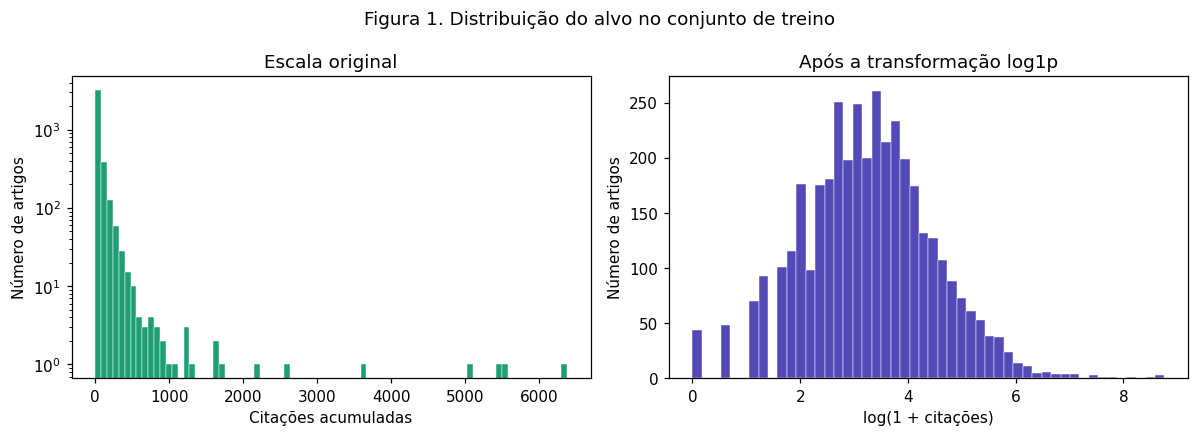

In [16]:
fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
eixos[0].hist(y_treino, bins=80, color=verdin, edgecolor="white", linewidth=0.3)
eixos[0].set_xlabel("Citações acumuladas")
eixos[0].set_ylabel("Número de artigos")
eixos[0].set_title("Escala original")
eixos[0].set_yscale("log")
eixos[1].hist(z_treino, bins=50, color=roxin, edgecolor="white", linewidth=0.3)
eixos[1].set_xlabel("log(1 + citações)")
eixos[1].set_ylabel("Número de artigos")
eixos[1].set_title("Após a transformação log1p")
fig.suptitle("Figura 1. Distribuição do alvo no conjunto de treino")
figura("01_distribuicao_alvo.png")

<div style="text-align: justify; max-width: 96%">

Veja que, na escala original, quase todos os artigos se amontoam nas primeiras barras, e a cauda se estende até mais de 5000 citações, com barras isoladas de um ou dois artigos. Depois da transformação, a distribuição fica aproximadamente simétrica, em forma de sino, com o centro entre 3 e 4 na escala logarítmica. As barras isoladas na ponta esquerda não são um defeito: como as citações são números inteiros, os primeiros valores possíveis (0, 1, 2 citações...) ficam separados por saltos visíveis na escala logarítmica, e a barra em zero corresponde aos 27 artigos sem nenhuma citação.

O argumento de fundo é sobre o que o erro quadrático faz. Na escala original, errar por 1000 citações contribui com um milhão para a soma, enquanto errar por 10 contribui com apenas cem, de modo que o modelo gastaria toda a sua capacidade com a cauda excepcional e erraria os artigos típicos. Na escala `log1p`, errar por um fator de dez pesa aproximadamente o mesmo, seja o artigo pouco ou muito citado, isto é, a penalidade passa a ser sobre o erro relativo.

</div>

<div style="text-align: justify; max-width: 96%">

Como os dados coletados nem sempre estão completamente preenchidos (isso é, existem dados ausentes e até dados ambíguos - o zero, para o PubMed, pode representar tanto ausência quanto "0" de fato). Nesse sentido, é cabível debruçar-se sobre esses dados:

</div>

In [17]:
ausencia = (df_treino[ATRIBUTOS].isna().mean() * 100).round(2)
ausencia = ausencia[ausencia > 0].sort_values(ascending=False)
print("Valores ausentes na matriz de atributos:",
      "nenhum" if len(ausencia) == 0 else "")
if len(ausencia):
    print(ausencia.to_string())

colunas_de_contagem = ["n_mesh", "n_keywords", "n_financiamentos",
                       "n_referencias_pubmed", "n_afiliacoes",
                       "n_referencias", "n_instituicoes"]
porcentagem_de_zeros = {c: float((df_treino[c].fillna(0) == 0).mean() * 100) for c in colunas_de_contagem}

print("\nContagens em zero (possível ausência de registro, não do atributo):")
for coluna, pct in sorted(porcentagem_de_zeros.items(), key=lambda kv: -kv[1]):
    print(f"  {coluna:22s} {pct:5.1f}%")

Valores ausentes na matriz de atributos: nenhum

Contagens em zero (possível ausência de registro, não do atributo):
  n_financiamentos        71.3%
  n_mesh                  36.6%
  n_referencias_pubmed    32.5%
  n_keywords              29.1%
  n_afiliacoes             7.6%
  n_instituicoes           1.0%
  n_referencias            0.7%


<div style="text-align: justify; max-width: 96%">

Não há nenhum valor ausente na matriz de atributos, mas isso não quer dizer que a informação esteja completa: os zeros ocupam o lugar das ausências. O caso mais extremo é o número de financiamentos, zerado em 71,4% dos artigos do treino - é improvável que sete em cada dez artigos não tenham tido financiamento algum, então o zero, aqui, deve significar na maior parte das vezes que o financiamento não foi registrado. Em seguida vêm os termos MeSH (35,8%), as referências registradas no PubMed (33,3%) e as palavras-chave (28,1%), que também dependem do que a revista e a indexação depositam. Já as afiliações (7,2%), as instituições (0,9%) e o número total de referências (0,6%) quase sempre estão presentes. Como não é possível separar o zero verdadeiro do zero por falta de registro, os atributos foram mantidos como estão, e cabe ao modelo aprender o que cada zero significa (a taxa, por sua vez, fica documentada aqui, ao invés de escondida).

</div>

<div style="text-align: justify; max-width: 96%">

Em seguida, a relação entre idade e impacto, em duas leituras. A função `stats.spearmanr` mede a correlação de postos, isto é, se a relação é monótona, sem supor que ela seja uma reta (e não há nenhuma razão para que a relação entre idade e citações seja linear). Já o `groupby` sobre `idade_dias // 365` agrupa os artigos por anos completos de idade, e a mediana de cada grupo é mais informativa que a média, pelo mesmo motivo de cauda longa discutido acima.

</div>

Correlação de postos entre idade e citações: 0.387


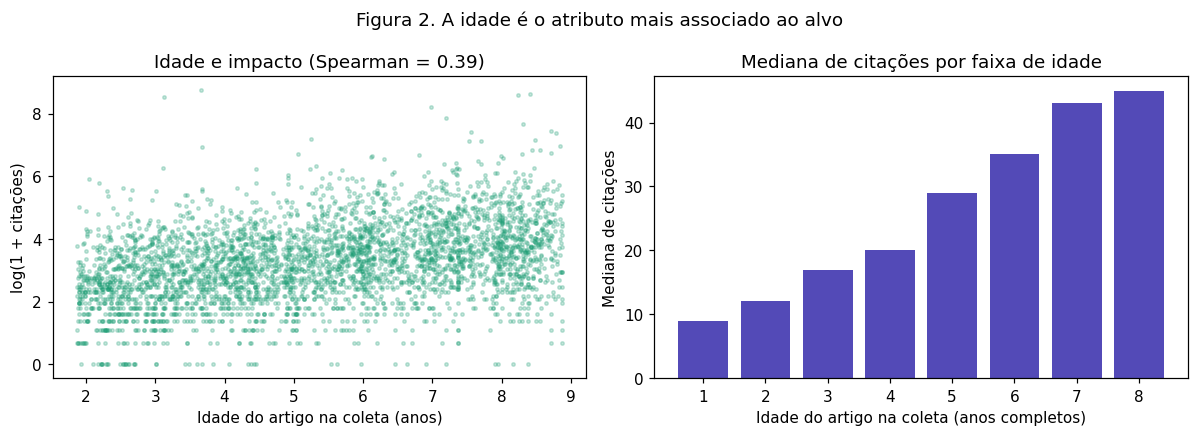

In [18]:
idade = df_treino["idade_dias"].to_numpy()
spearman_idade = float(stats.spearmanr(idade, y_treino).statistic)
print(f"Correlação de postos entre idade e citações: {spearman_idade:.3f}")

mediana_por_idade = df_treino.groupby(df_treino["idade_dias"] // 365)[ALVO].agg(["median", "count"])

fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
eixos[0].scatter(idade / 365, z_treino, s=5, alpha=0.25, color=verdin)
eixos[0].set_xlabel("Idade do artigo na coleta (anos)")
eixos[0].set_ylabel("log(1 + citações)")
eixos[0].set_title(f"Idade e impacto (Spearman = {spearman_idade:.2f})")
eixos[1].bar(mediana_por_idade.index, mediana_por_idade["median"], color=roxin)
eixos[1].set_xlabel("Idade do artigo na coleta (anos completos)")
eixos[1].set_ylabel("Mediana de citações")
eixos[1].set_title("Mediana de citações por faixa de idade")
fig.suptitle("Figura 2. A idade é o atributo mais associado ao alvo")
figura("02_idade_citacoes.png")

<div style="text-align: justify; max-width: 96%">

No painel da esquerda, a nuvem de pontos sobe com a idade, mas com uma dispersão enorme em todas as faixas: há artigos de dois anos com mais citações que muitos de oito. No painel da direita, a mediana cresce de forma quase monótona, de cerca de 8 citações para os artigos com 1 ano completo até cerca de 44 para os com 8 anos, com um patamar entre 6 e 8 anos. Isso confirma que a contagem de citações mede, em boa parte, o tempo que o artigo teve para ser citado, e justifica manter a idade como atributo de controle (como discutido na limpeza): sem ela, o modelo confundiria um artigo recente com um artigo pouco relevante.

</div>

<div style="text-align: justify; max-width: 96%">

Saindo desse atributo específico, medimos a correlação de cada atributo com o alvo, calculada uma a uma. No gráfico, as cores distinguem associação positiva (verde) de negativa (laranja), e a ordenação é pelo valor com sinal, de modo que os dois extremos fiquem nas pontas.

</div>

Cinco maiores em módulo:
  idade_dias                 +0.387
  n_referencias              +0.270
  n_tipos_publicacao         +0.177
  eh_revisao                 +0.154
  n_instituicoes             +0.126


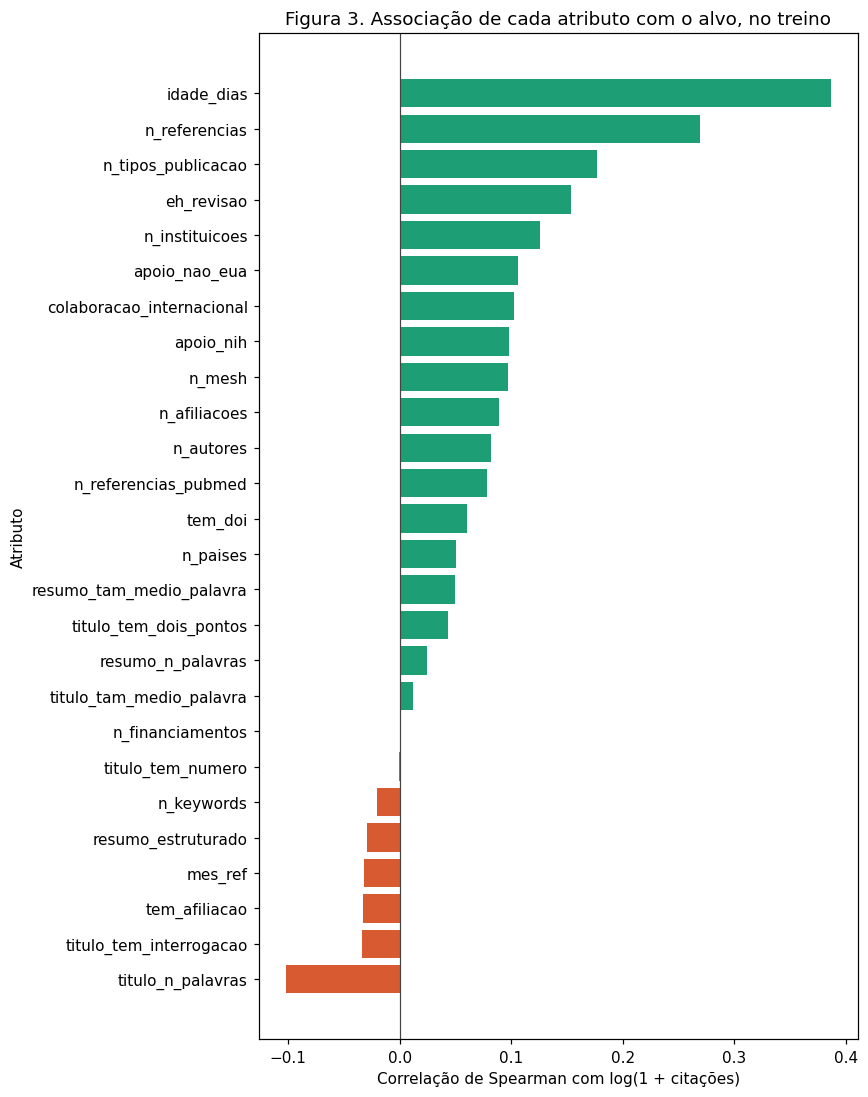

In [19]:
correlacoes = {}
for coluna in NUMERICOS + BINARIOS:
    valores = df_treino[coluna].astype(float)
    esconde = valores.notna() 
    if esconde.sum() > 30 and valores[esconde].nunique() > 1:
        correlacoes[coluna] = float(
            stats.spearmanr(valores[esconde], z_treino[esconde.to_numpy()]).statistic)
    # notna e nunquine > 1 evitam tentar o calculo com colunas constantes ou quase vazia

correlacoes_em_ordem = pd.Series(correlacoes).sort_values()

print("Cinco maiores em módulo:")
mais_fortes = correlacoes_em_ordem.reindex(correlacoes_em_ordem.abs().sort_values(ascending=False).index).head(5)
for coluna, valor in mais_fortes.items():
    print(f"  {coluna:26s} {valor:+.3f}")

plt.figure(figsize=(8, 0.33 * len(correlacoes_em_ordem) + 1.5))
cores = [verdin if v > 0 else laranjin for v in correlacoes_em_ordem.values]
plt.barh(correlacoes_em_ordem.index, correlacoes_em_ordem.values, color=cores)
plt.axvline(0, color=cinzin, linewidth=0.8)
plt.xlabel("Correlação de Spearman com log(1 + citações)")
plt.ylabel("Atributo")
plt.title("Figura 3. Associação de cada atributo com o alvo, no treino")
figura("03_correlacao_alvo.png")

<div style="text-align: justify; max-width: 96%">

A idade lidera com folga (+0,388), seguida pelo número de referências (+0,273), pelo número de tipos de publicação (+0,202), pelo indicador de revisão (+0,152) e pelo número de instituições (+0,135). Fora a idade, todas as associações são fracas, o que já sugere que nenhum atributo isolado carrega muita informação sobre o alvo e que o desempenho dos modelos será limitado. Perceba também que os atributos positivos mais fortes descrevem o tipo de artigo (revisões costumam ter listas de referências longas e mais tipos de publicação registrados) e o tamanho da colaboração (autores, afiliações, instituições e países), enquanto, entre os negativos, o mais forte é o número de palavras do título (títulos mais longos, ligeiramente menos citados). Vale denotar que isso são associações, e não causas (e que, portanto, esse resultado não sugere que um cientista infle suas referências como tentativa de que seu artigo seja mais citado).

</div>

<div style="text-align: justify; max-width: 96%">

Em seguida, a busca por pares de atributos colineares, isto é, que carregam praticamente a mesma informação. O laço duplo percorre cada par de atributos numéricos uma única vez (usando `NUMERICOS[i + 1:]`, para não repetir pares nem comparar uma coluna com ela mesma) e guarda os que passam de 0,70 em módulo, um limiar convencional.
</div>

Pares com correlação de postos acima de 0,70 em módulo:
  nenhum


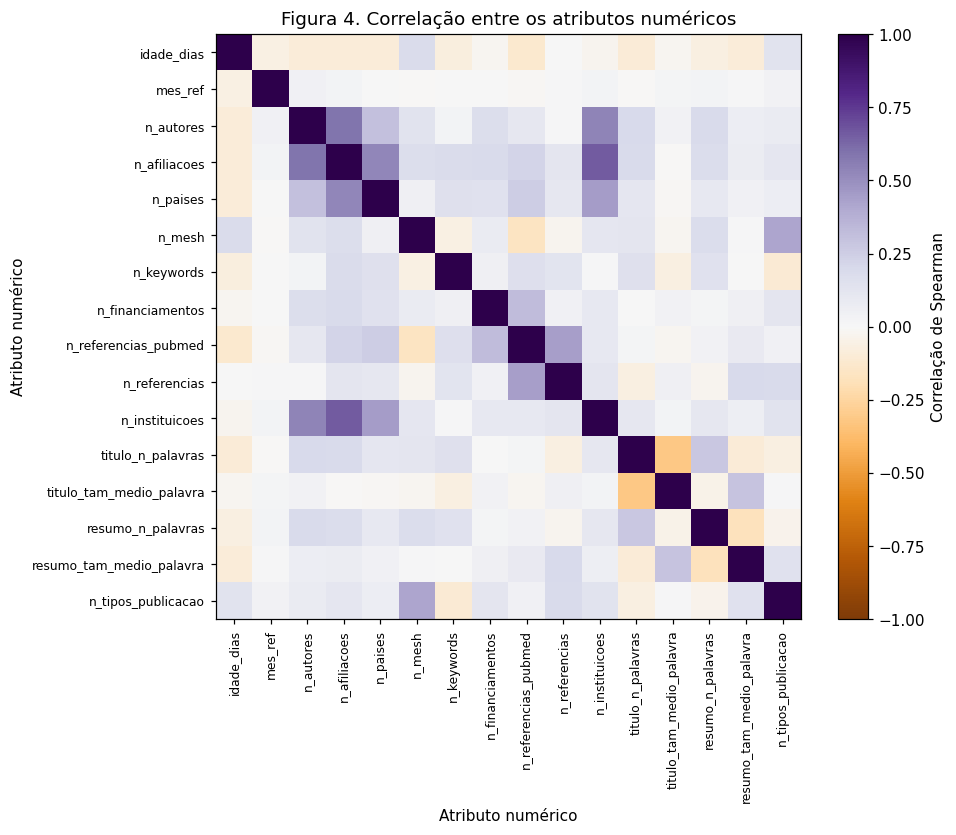

In [20]:
matriz = df_treino[NUMERICOS].corr(method="spearman")

pares_colineares = []
for i, a in enumerate(NUMERICOS):
    for b in NUMERICOS[i + 1:]:
        valor = float(matriz.loc[a, b])
        if abs(valor) >= 0.70:
            pares_colineares.append((a, b, valor))

print("Pares com correlação de postos acima de 0,70 em módulo:")
if pares_colineares:
    for a, b, valor in pares_colineares:
        print(f"  {a} x {b}: {valor:+.2f}")
else:
    print("  nenhum")

plt.figure(figsize=(9, 7.5))
plt.imshow(matriz, cmap="PuOr", vmin=-1, vmax=1)
plt.colorbar(label="Correlação de Spearman")
plt.xticks(range(len(NUMERICOS)), NUMERICOS, rotation=90, fontsize=8)
plt.yticks(range(len(NUMERICOS)), NUMERICOS, fontsize=8)
plt.xlabel("Atributo numérico")
plt.ylabel("Atributo numérico")
plt.title("Figura 4. Correlação entre os atributos numéricos")
figura("04_colinearidade.png")

<div style="text-align: justify; max-width: 96%">

Nenhum par passou do limiar de 0,70, de modo que nenhum atributo numérico precisou ser descartado por redundância. A Figura 4 mostra, ainda assim, alguns blocos com correlação moderada: o tamanho da colaboração (número de autores, afiliações, instituições e países), as duas contagens de referências (a do PubMed e a total) e o par formado pelo número de termos MeSH e pelo número de tipos de publicação. O número de palavras do título e o tamanho médio das palavras do título têm correlação negativa, o que faz sentido, já que títulos longos costumam ter mais palavras curtas (artigos e preposições). Essas correlações moderadas não atrapalham os modelos, já que nenhum par chega perto de carregar a mesma informação.

Por fim, o perfil das categóricas. Para cada uma, calculam-se três números: quantos níveis (valores distintos) existem, quantos têm pelo menos dez artigos e que fração do conjunto esses níveis cobrem. O gráfico, por sua vez, mostra a mediana de citações por área, filtrando as áreas com menos de trinta artigos (a mediana de um grupo muito pequeno é instável demais para ser lida) - é nesse momento que realmente identificamos a alta cardinalidade supracitada.

</div>

,níveis,níveis com 10+ artigos,cobertura desses níveis (%)
revista,1319.0,69.0,41.1
topico_principal,948.0,66.0,50.2
tipo_revista_oa,4.0,4.0,100.0
area_principal,26.0,22.0,99.6


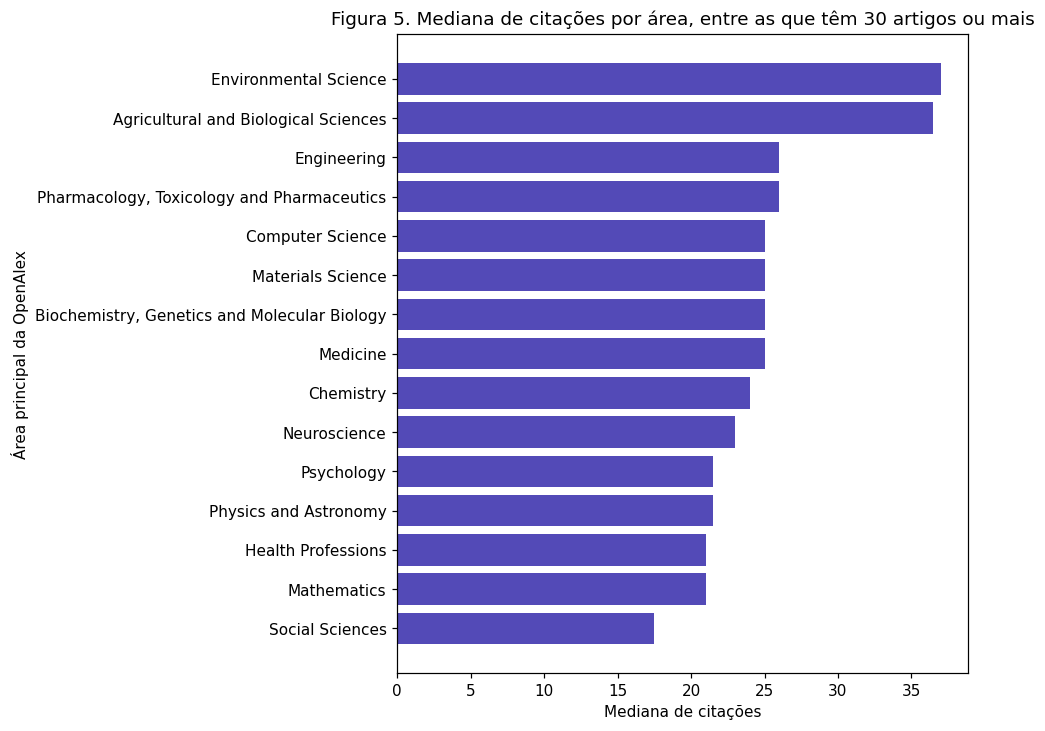

In [21]:
perfil_categoricas = {}
for coluna in CATEGORICOS:
    contagem = df_treino[coluna].value_counts()
    perfil_categoricas[coluna] = {
        "níveis": int(df_treino[coluna].nunique()),
        "níveis com 10+ artigos": int((contagem >= 10).sum()),
        "cobertura desses níveis (%)": round(
            float(100 * contagem[contagem >= 10].sum() / len(df_treino)), 1),
    }
display(pd.DataFrame(perfil_categoricas).T)

areas = (df_treino.groupby("area_principal")[ALVO].agg(["median", "count"])
         .query("count >= 30").sort_values("median", ascending=False))

plt.figure(figsize=(9, 0.35 * len(areas) + 1.5))
plt.barh(areas.index[::-1], areas["median"].values[::-1], color=roxin)
plt.xlabel("Mediana de citações")
plt.ylabel("Área principal da OpenAlex")
plt.title("Figura 5. Mediana de citações por área, entre as que têm 30 artigos ou mais")
figura("05_area_citacoes.png")

<div style="text-align: justify; max-width: 96%">

A tabela mostra o problema da alta cardinalidade com clareza: há 1318 revistas diferentes no treino, das quais apenas 64 têm dez artigos ou mais, e essas 64 cobrem só 40,2% dos artigos; com os tópicos, são 947 níveis, 66 com dez artigos ou mais, cobrindo 50,5%. Em outras palavras, mais da metade dos artigos está em uma revista que aparece menos de dez vezes no treino, e cerca de metade está em um tópico nessa mesma situação. Já o tipo de revista (4 níveis) e a área (25 níveis, dos quais 22 cobrem 99,6% dos artigos) são bem comportados. A Figura 5 mostra que a área carrega alguma informação sobre o alvo: a mediana de citações vai de cerca de 17, em ciências sociais, a cerca de 37, em psicologia, com medicina e ciência da computação no meio do caminho.

Codificar revistas e tópicos diretamente em variáveis indicadoras (*one-hot*) produziria uma matriz quase tão larga quanto alta, o que atrapalharia de três formas: para o KNN, distâncias em dimensão muito alta perdem poder de discriminação; para a regressão regularizada, sobram colunas e faltam exemplos; e, para as árvores, cada coluna indicadora é quase sempre zero, de modo que nenhuma divisão sobre ela separa um número útil de exemplos.

</div>

## 4. Pipelines e otimização de hiperparâmetros com o Optuna

#### O que é um pipeline?

<div style="text-align: justify; max-width: 96%">

Primeiramente, é essencial entender o que é um pipeline. Um `Pipeline` do scikit-learn é uma sequência de etapas em que todas, menos a última, são transformadores (que mexem diretamente nos dados) e a última é um estimador (o modelo propriamente dito). O objeto inteiro tem `fit` e `predict`, e se comporta como se fosse um único modelo.

Quando se chama o comando `fit`, cada transformador aprende seus parâmetros nos dados que recebeu naquela chamada (apenas neles); quando se chama o comando `predict`, os transformadores apenas aplicam o que aprenderam.


</div>

#### A estrutura comum a todos os modelos

<div style="text-align: justify; max-width: 96%">

Todos os modelos deste relatório compartilham o mesmo protocolo, seguindo os objetivos estipulados no início:

- **alvo:** todos preveem `z = log1p(citações)`, e as métricas em citações reais são obtidas desfazendo a transformação com `expm1`;

- **pré-processamento:** os blocos do esquema acima. A escala e o tipo de codificação variam por algoritmo, pela razão explicada em cada seção;

- **categóricas de alta cardinalidade:** `revista` e `topico_principal` passam por um transformador que mantém apenas as categorias com pelo menos `min_frequencia` ocorrências e junta o resto em `outras`. Como esse conjunto de categorias frequentes é aprendido no ajuste, uma revista que apareça só na dobra de validação cai em `outras` - o que já emula o que aconteceria com uma revista nova no momento de uma previsão real;

- **validação cruzada:** cinco dobras, com `KFold`. As mesmas cinco partições são usadas por todos os algoritmos e pelo baseline, o que torna a comparação pareada: para cada artigo, existe uma previsão vinda de um modelo que não o viu no treino;

- **otimização:** Optuna com exatamente 100 trials por algoritmo e `TPESampler`. O TPE (*tree-structured Parzen estimator*) separa os trials já avaliados em bons e ruins, estima a distribuição dos hiperparâmetros em cada grupo e sorteia o próximo ponto onde os bons são mais prováveis que os ruins. Assim, ele difere da busca aleatória por aprender com os trials anteriores, e da busca em grade por não gastar avaliações em dimensões que não importam.

</div>

#### As métricas

<div style="text-align: justify; max-width: 96%">

Para avaliar os modelos, utilizam-se três métricas, cada uma escrita em uma função pequena, para que o resto do notebook as chame sempre do mesmo jeito:

- **RMSE na escala log** (`rmse_log`), a raiz do erro quadrático médio em `log1p(citações)`, e essa será a métrica que o Optuna minimiza, pois penaliza o erro relativo, como discutido na análise exploratória:

$$\mathrm{RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^{n} (z_i - \hat{z}_i)^2}, \qquad z_i = \log(1 + y_i)$$

- **MAE em citações** (`mae_real`), o erro absoluto médio depois de desfazer o `log1p` com `expm1` - serve como a métrica de leitura, em uma unidade mais palatável ao entendimento:

$$\mathrm{MAE} = \frac{1}{n}\sum_{i=1}^{n} \left| y_i - (e^{\hat{z}_i} - 1) \right|$$

- **correlação de Spearman** (`spearman`), que compara a ordem prevista para os artigos e a ordem real deles. No caso abordado, é equivalente a criar uma fila dos artigos a partir de quantas citações se previu que ele tenha e então comparar essa fila à fila real. Quando o modelo prevê sempre o mesmo valor, essa correlação não é definida (o denominador zera), e o código a trata como zero: o modelo não distingue artigo nenhum de outro.

</div>

In [ ]:
def rmse_log(z_verdadeiro, z_previsto):
    z_verdadeiro, z_previsto = np.asarray(z_verdadeiro), np.asarray(z_previsto)
    return float(np.sqrt(np.mean((z_verdadeiro - z_previsto) ** 2)))


def mae_real(z_verdadeiro, z_previsto):
    y = np.expm1(np.asarray(z_verdadeiro))
    # desfaz o llogp1
    previsto = np.expm1(np.clip(np.asarray(z_previsto), 0, None))
    # np.clip tira qlqr número negativo - ñ faz sentido com 
    return float(np.mean(np.abs(y - previsto)))


def spearman(z_verdadeiro, z_previsto):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        resultado = spearmanr(z_verdadeiro, z_previsto).statistic
    return float(resultado) if np.isfinite(resultado) else 0.0


def todas_as_metricas(z_verdadeiro, z_previsto):
    return {
        "rmse_log": rmse_log(z_verdadeiro, z_previsto),
        "mae_real": mae_real(z_verdadeiro, z_previsto),
        "spearman": spearman(z_verdadeiro, z_previsto),
    }

Métricas definidas: rmse_log, mae_real, spearman


<div style="text-align: justify; max-width: 96%">

Agora, o transformador customizado que agrupa as categorias raras, como foi amplamente discutido anteriormente.
</div>

In [23]:
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (OneHotEncoder, OrdinalEncoder,
                                   QuantileTransformer, StandardScaler)


class agrupando_raros(BaseEstimator, TransformerMixin):
    def __init__(self, min_frequencia=10):
        self.min_frequencia = min_frequencia

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.colunas_ = list(X.columns)
        self.frequentes_ = {}
        for coluna in self.colunas_:
            contagem = X[coluna].astype("object").value_counts()
            self.frequentes_[coluna] = set(contagem[contagem >= self.min_frequencia].index)
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        for coluna in self.colunas_:
            frequentes = self.frequentes_[coluna]
            valores = X[coluna].astype("object")
            X[coluna] = valores.where(valores.isin(frequentes), "outras")
        return X

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.colunas_, dtype=object)


print("agrupando_raros definido")

agrupando_raros definido


<div style="text-align: justify; max-width: 96%">

Em seguida, duas funções e uma constante:

- `bloco_categorico` monta o pipeline das categóricas (agrupar as raras e depois codificar). O codificador é escolhido pelo argumento, porque modelos lineares e de distância precisam de variáveis indicadoras, enquanto as árvores funcionam bem com codificação ordinal e ficam com uma matriz muito mais estreita;
- `preprocessamento` monta o `ColumnTransformer` com os três blocos. O argumento `escala` aceita `"nenhuma"`, usado pelos modelos de árvore, que não mudam quando um atributo passa por uma transformação monótona e, portanto, não ganham nada com padronização;
- `PARTICOES` é criada uma única vez, fora de qualquer função, e reutilizada por todos os algoritmos e pelo baseline - assim permitindo a comparação justa entre os modelos.

</div>

In [24]:
def bloco_categorico(min_frequencia, tipo):
    codificador = (OneHotEncoder(handle_unknown="ignore", sparse_output=False)
                   if tipo == "onehot"
                   else OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))
    return Pipeline([("agrupa", agrupando_raros(min_frequencia=min_frequencia)),
                     ("codifica", codificador)])


def preprocessamento(min_frequencia, escala="standard", codificacao="onehot"):
    if escala == "standard":
        escalador = StandardScaler()
    elif escala == "quantil":
        escalador = QuantileTransformer(output_distribution="normal",
                                        n_quantiles=500, random_state=SEMENTE)
    else:
        escalador = "passthrough"

    numerico = Pipeline([("imputa", SimpleImputer(strategy="median")),
                         ("escala", escalador)])

    return ColumnTransformer(
        [("num", numerico, NUMERICOS),
         ("bin", "passthrough", BINARIOS),
         ("cat", bloco_categorico(min_frequencia, codificacao), CATEGORICOS)],
        remainder="drop", verbose_feature_names_out=False)


# particoes feitas antes dos modelos serem fitados - sao sempre as mesmas e permite compara-los
PARTICOES = list(KFold(n_splits=N_DOBRAS, shuffle=True, random_state=SEMENTE)
                 .split(np.arange(len(z_treino))))

print(f"{N_DOBRAS} partições fixadas pela semente {SEMENTE}")
for i, (tr, va) in enumerate(PARTICOES, 1):
    print(f"  dobra {i}: {len(tr)} de treino, {len(va)} de validação")

5 partições fixadas pela semente 19
  dobra 1: 3102 de treino, 776 de validação
  dobra 2: 3102 de treino, 776 de validação
  dobra 3: 3102 de treino, 776 de validação
  dobra 4: 3103 de treino, 775 de validação
  dobra 5: 3103 de treino, 775 de validação


<div style="text-align: justify; max-width: 96%">

Note que cada dobra tem 3094 ou 3095 artigos de treino e 774 ou 773 de validação, isto é, os 3868 artigos do treino divididos em cinco partes quase iguais. Como as partições são fixadas pela semente 19 e reutilizadas por todos os modelos, as comparações entre eles são feitas exatamente sobre as mesmas divisões.

Com isso, chega-se às quatro funções que todo o resto da seção usa:

- `avalia` roda a validação cruzada. A linha central é `modelo.fit(X.iloc[treino_idx], ...)`: é o pipeline inteiro que entra em cada dobra, e é isso que faz a imputação, a escala e a codificação serem ajustadas só na parte de treino. As previsões são guardadas nas posições de validação, de modo que, ao fim, cada artigo tenha exatamente uma previsão, vinda de um modelo que não o viu;
- `guarda_resultado` grava o resultado de cada modelo em disco, e `mostra_resultado` o imprime sempre no mesmo formato. As saídas ficam reunidas por tipo, e não espalhadas em um arquivo por modelo: `melhores_modelos.json` guarda um dicionário com o registro de cada modelo (um dicionário de dicionários) e `historicos.csv` guarda todos os trials de todos os modelos, identificados pela coluna `modelo`;
- `roda_otimizacao` faz o trabalho pesado. Perceba a primeira coisa que ela faz: se o modelo já estiver em `melhores_modelos.json`, o resultado é reaproveitado, o que permite rodar o notebook inteiro de novo em poucos minutos. A função objetivo pede os hiperparâmetros ao `trial`, roda a validação cruzada e devolve a média do RMSE entre as dobras;
- `grafico_convergencia` lê, em `historicos.csv`, as linhas do modelo pedido e desenha o melhor valor obtido até cada trial (com `cummin`), que é a forma usual de visualizar se a busca ainda estava melhorando quando acabou.

</div>

In [ ]:
import optuna

# Um arquivo por TIPO de saída, e não um por modelo:
#   melhores_modelos.json  dicionário de dicionários, um registro por modelo
#   historicos.csv         todos os trials de todos os modelos (coluna "modelo")
ARQUIVO_MELHORES = os.path.join(SAIDAS, "melhores_modelos.json")
ARQUIVO_HISTORICOS = os.path.join(SAIDAS, "historicos.csv")


def avalia(utilizado, parametros, X, z, particoes=None):
    particoes = PARTICOES if particoes is None else particoes
    previsoes = np.zeros(len(z), dtype=float)
    rmses = []
    for treino_idx, validacao_idx in particoes:
        modelo = utilizado(parametros) if parametros is not None else clone(utilizado())
        modelo.fit(X.iloc[treino_idx], z[treino_idx])
        p = modelo.predict(X.iloc[validacao_idx])
        previsoes[validacao_idx] = p
        rmses.append(rmse_log(z[validacao_idx], p))
    return previsoes, np.array(rmses)


def le_melhores():
    """Devolve o dicionário {modelo: registro} já gravado (ou um vazio)."""
    if not os.path.exists(ARQUIVO_MELHORES):
        return {}
    with open(ARQUIVO_MELHORES, encoding="utf-8") as arquivo:
        return json.load(arquivo)


def guarda_resultado(nome, parametros, rmses, previsoes, n_trials, segundos=None, extra=None):
    registro = {
        "algoritmo": nome,
        "n_trials": n_trials,
        "melhores_hiperparametros": parametros,
        "rmse_log_por_dobra": rmses.tolist(),
        "rmse_log_medio": float(rmses.mean()),
        "rmse_log_desvio": float(rmses.std()),
        "metricas": todas_as_metricas(z_treino, previsoes),
        "segundos": segundos,
    }
    if extra:
        registro.update(extra)

    # o registro entra (ou é substituído) no dicionário de todos os modelos
    melhores = le_melhores()
    melhores[nome] = registro
    with open(ARQUIVO_MELHORES, "w", encoding="utf-8") as arquivo:
        json.dump(melhores, arquivo, ensure_ascii=False, indent=2)
    return registro


def guarda_historico(nome, historico):
    """Junta os trials de um modelo à tabela de históricos de todos os modelos."""
    historico = historico.copy()
    historico.insert(0, "modelo", nome)
    if os.path.exists(ARQUIVO_HISTORICOS):
        antigos = pd.read_csv(ARQUIVO_HISTORICOS)
        antigos = antigos[antigos["modelo"] != nome]   # substitui, não duplica
        historico = pd.concat([antigos, historico], ignore_index=True)
    historico.to_csv(ARQUIVO_HISTORICOS, index=False)


def mostra_resultado(registro):
    m = registro["metricas"]
    print(f"  RMSE log  {registro['rmse_log_medio']:.4f} "
          f"(desvio entre dobras {registro['rmse_log_desvio']:.4f})")
    print(f"  MAE       {m['mae_real']:.2f} citações")
    print(f"  Spearman  {m['spearman']:.3f}")
    if registro.get("segundos"):
        print(f"  tempo     {registro['segundos']/60:.1f} min")


def roda_otimizacao(nome, espaco, utilizado, n_trials=N_TRIALS, recalcular=False):
    melhores = le_melhores()
    if nome in melhores and not recalcular:
        print(f"[{nome}] resultado reaproveitado de {ARQUIVO_MELHORES}")
        mostra_resultado(melhores[nome])
        return melhores[nome]

    optuna.logging.set_verbosity(optuna.logging.WARNING)
    inicio = time.time()

    def objetivo(trial):
        parametros = espaco(trial)
        previsoes, rmses = avalia(utilizado, parametros, X_treino, z_treino)
        trial.set_user_attr("desvio_entre_dobras", float(rmses.std()))
        return float(rmses.mean())

    estudo = optuna.create_study(direction="minimize",
                                 sampler=optuna.samplers.TPESampler(seed=SEMENTE),
                                 study_name=nome)
    estudo.optimize(objetivo, n_trials=n_trials, show_progress_bar=False)

    previsoes, rmses = avalia(utilizado, estudo.best_params, X_treino, z_treino)
    guarda_historico(nome, estudo.trials_dataframe())
    registro = guarda_resultado(nome, estudo.best_params, rmses, previsoes,
                                n_trials, time.time() - inicio)
    print(f"[{nome}] {n_trials} trials concluídos")
    mostra_resultado(registro)
    return registro


def grafico_convergencia(nome, titulo):
    """Mostra como o melhor RMSE evoluiu ao longo dos trials."""
    if not os.path.exists(ARQUIVO_HISTORICOS):
        print("(o arquivo de históricos ainda não existe)")
        return
    historico = pd.read_csv(ARQUIVO_HISTORICOS)
    historico = (historico[historico["modelo"] == nome]
                 .dropna(subset=["value"]).sort_values("number"))
    if historico.empty:
        print(f"(histórico de {nome} ainda não existe)")
        return
    melhor_ate_agora = historico["value"].cummin()
    plt.figure(figsize=(7.5, 3.2))
    plt.plot(historico["number"], historico["value"], "o", ms=3,
             alpha=0.35, color=roxin, label="trial")
    plt.plot(historico["number"], melhor_ate_agora, color=laranjin,
             linewidth=1.6, label="melhor até este ponto")
    plt.xlabel("Trial")
    plt.ylabel("RMSE em log(1 + citações)")
    plt.title(titulo)
    plt.legend(frameon=False)
    figura(f"conv_{nome}.png")

Definiu: avalia, le_melhores, guarda_resultado, guarda_historico,
         mostra_resultado, roda_otimizacao, grafico_convergencia


### 4.1. Baseline

<div style="text-align: justify; max-width: 96%">

O baseline é um modelo extremamente simples que é usado para necessário estabelecer uma referência. Ele existe para marcar o piso de desempenho, e não para competir - motivo pelo qual ele não passa pelo Optuna (otimizá-lo tira seu posto de "baseline").

O baseline escolhido é um `DummyRegressor` com a **mediana** (como visto na Análise Exploratória, a mediana é mais representativa do que a média no nosso conjunto de dados), que prevê sempre o mesmo valor. Ele responde à pergunta mais básica que se pode fazer a qualquer modelo: ele faz melhor do que chutar o valor central?

No código, o dicionário `resultados` criado aqui acumula o registro de todos os modelos ao longo da seção, para que eles possam ser adequadamente comparados posteriormente.

</div>

In [26]:
from sklearn.dummy import DummyRegressor


def baseline_mediana():
    return Pipeline([("modelo", DummyRegressor(strategy="median"))])


resultados = {}

previsoes, rmses = avalia(baseline_mediana, None, X_treino, z_treino)
resultados["baseline_mediana"] = guarda_resultado(
    "baseline_mediana", "não otimizado, por ser baseline", rmses, previsoes, 0)
print("[baseline_mediana]")
mostra_resultado(resultados["baseline_mediana"])

[baseline_mediana]
  RMSE log  1.2152 (desvio entre dobras 0.0371)
  MAE       50.39 citações
  Spearman  -0.018


<div style="text-align: justify; max-width: 96%">

A mediana obteve RMSE de 1,1936 na escala logarítmica (com desvio de 0,0130 entre as dobras) e MAE de 48,47 citações - qualquer pipeline que não fique abaixo desses valores não está aprendendo nada de útil. A correlação de Spearman de -0,015 é, na prática, zero, como esperado de um modelo que prevê sempre o mesmo valor - ela só não é exatamente zero porque a mediana é recalculada no treino de cada dobra e pode mudar ligeiramente de uma dobra para outra, de modo que as previsões fora da dobra não são todas idênticas.

</div>

### 4.2. Rigde

#### 4.2.1. O algoritmo

<div style="text-align: justify; max-width: 96%">

O Rigde é uma regressão linear com penalização L2 **(veja a Esfinge do Vinícius Mariano no repositório "biblioteca real" no *github*)**: ao erro quadrático soma-se `alpha` vezes a soma dos quadrados dos coeficientes, o que encolhe os coeficientes na direção de zero sem zerá-los.

$$\min_{\beta} \; \sum_{i=1}^{n} (z_i - \mathbf{x}_i^\top \beta)^2 + \alpha \sum_{j=1}^{p} \beta_j^2$$

Esse encolhimento tende a produzir uma "grande" redução na variância, mas aumenta apenas um pouco o viés, o que, por conseguinte, é benéfico ao balaço viés-variância (claro, sob um $\alpha$ "bom")

Por ser o mais simples dos modelos utilizados, o Rigde também funciona como régua para os demais: se um modelo mais complexo não bater um modelo linear muito mais simples (caso, por exemplo, o XGBoost tenha desempenho inferior ao Rigde), ele não justifica a própria complexidade. Perceba, no entanto, que o Rigde não é um baseline: ao contrário da mediana, ele passa pelo Optuna como qualquer outro pipeline, fazendo com que a comparação com os modelos mais complexos seja justa.

</div>

#### 4.2.2. Hiperparâmetros e Optuna

<div style="text-align: justify; max-width: 96%">

Os intervalos escolhidos foram:

- `alpha`, de 0,001 a 1000, em escala logarítmica. Perto de 0,001, o Rigde praticamente vira uma regressão linear comum; perto de 1000, os coeficientes ficam tão encolhidos que o modelo se aproxima de prever a média. Como o efeito do `alpha` atua em ordens de grandeza, a escala logarítmica é a natural;
- `escala`, entre a padronização (`standard`) e a transformação por quantis (`quantil`). Alguma escala é obrigatória aqui, já que a penalização trata todos os coeficientes igualmente e, sem ela, um atributo medido em uma escala grande teria um coeficiente pequeno e, portanto, seria menos penalizado; a transformação por quantis é testada porque várias contagens têm cauda longa;
- `min_frequencia`, de 5 a 400, com a mesma faixa dos demais pipelines.

No código, o padrão é o mesmo de todos os pipelines: `espaco_rigde` sorteia os hiperparâmetros e `constroi_rigde` monta o pipeline. A codificação das categóricas é a indicadora (*one-hot*), já que a ordinal imporia às revistas e aos tópicos uma ordem que não existe, e um modelo linear tentaria inferir algo a partir dessa informação sintética (o que não representa bem os dados).

</div>

In [27]:
from sklearn.linear_model import Ridge


def espaco_rigde(trial):
    return {
        "min_frequencia": trial.suggest_int("min_frequencia", 5, 400, log=True),
        "escala": trial.suggest_categorical("escala", ["standard", "quantil"]),
        "alpha": trial.suggest_float("alpha", 1e-3, 1e3, log=True),
    }


def constroi_rigde(p):
    return Pipeline([
        ("prep", preprocessamento(p["min_frequencia"], p["escala"], "onehot")),
        ("modelo", Ridge(alpha=p["alpha"])),
    ])


resultados["rigde"] = roda_otimizacao("rigde", espaco_rigde, constroi_rigde)

[rigde] resultado reaproveitado de saidas\melhores_modelos.json
  RMSE log  1.0117 (desvio entre dobras 0.0370)
  MAE       46.62 citações
  Spearman  0.560
  tempo     0.8 min


#### 4.2.3. Resultados

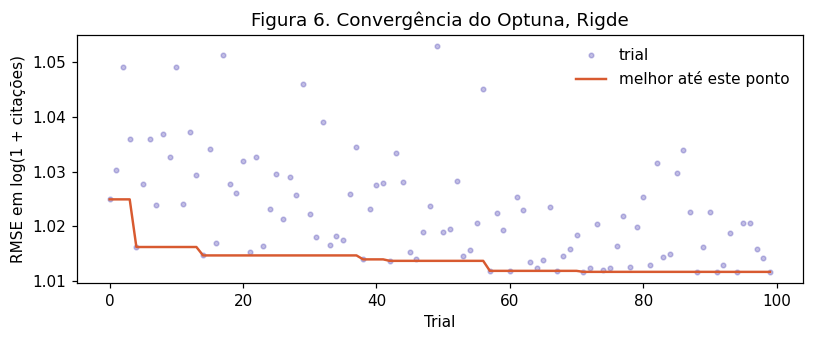

Hiperparâmetros vencedores:
  min_frequencia   5
  escala           standard
  alpha            9.7704


In [28]:
grafico_convergencia("rigde", "Figura 6. Convergência do Optuna, Rigde")

print("Hiperparâmetros vencedores:")
for chave, valor in resultados["rigde"]["melhores_hiperparametros"].items():
    valor = round(valor, 5) if isinstance(valor, float) else valor
    print(f"  {chave:16s} {valor}")

<div style="text-align: justify; max-width: 96%">

O Rigde atingiu RMSE de 0,9736 (desvio de 0,0333 entre as dobras), MAE de 43,60 citações e Spearman de 0,576, contra 1,1936, 48,47 e -0,015 da mediana. Isto é, um modelo linear com regularização já captura uma parte considerável da ordenação dos artigos.

Além disso, também obtemos informações significativas através da análise dos hiperparâmetros vencedores: o `alpha` de 10,59 fica um pouco acima do centro da faixa logarítmica (de 0,001 a 1000), o que indica uma regularização moderada, que não é nem desprezível e nem domina o modelo. A escala escolhida foi a padronização comum (`standard`), e o `min_frequencia` ficou em 5 (por estar na borda, é possível que valores ainda menores fossem melhores), o limite inferior da faixa: o Rigde preferiu manter o maior número possível de revistas e tópicos como colunas próprias, o que é coerente com a regularização, que dá conta de muitas colunas encolhendo os coeficientes das categorias raras.

Pela figura acima, a busca convergiu cedo: o melhor valor caiu bruscamente nos primeiros trials e, por volta do trial 30~40, já estava praticamente no valor final. Com apenas três hiperparâmetros, 100 trials são mais que suficientes.

È relevante notar, por fim, uma ressalva que vale para todos os modelos: a queda do MAE (de 48,47 para 43,60 citações) é modesta perto da queda do RMSE na escala logarítmica, porque o MAE em citações reais é dominado pelos artigos da cauda (que provavelmente nenhum modelo prevê bem de fato).

</div>

### 4.3. KNN

#### 4.3.1. O algoritmo

<div style="text-align: justify; max-width: 96%">

O algoritmo &#119896;-NN ("&#119896; vizinhos mais próximos") se baseia na hipótese de que dados similares ocupam regiões similares no espaço dos atributos. Ele não tem uma fase de treino no sentido usual: apenas guarda os exemplos e, para prever, encontra os &#119896; mais próximos (vale destacar que determinar o que é "mais próximo" é um hiperparâmetro do modelo) e devolve a média das respostas deles, possivelmente ponderada (outro hiperparâmetro) de alguma forma pela distância (e ainda outro hiperparâmetro). É um método local e não paramétrico, ou seja, não assume nenhuma forma para a função, e por isso consegue capturar relações irregulares que um modelo linear perderia.

Em compensação, é o método mais exposto aos problemas deste conjunto, e de duas formas: i) a distância depende da escala dos atributos, então a padronização é obrigatória; e ii) atributos irrelevantes entram no cálculo da distância com o mesmo peso dos relevantes, já que o &#119896;-NN não tem nenhuma noção de importância.

</div>

#### 4.3.2. Hiperparâmetros e Optuna

<div style="text-align: justify; max-width: 96%">

Os intervalos dos hiperparâmetros foram escolhidos da seguinte forma:

- `n_neighbors` (o &#119896;) vai de 3 a 100. O limite superior de 100 corresponde a cerca de 2,5% do treino, acima do qual a previsão se aproxima da mediana geral e o modelo degenera no próprio baseline (*underfitting*);
- `weights` escolhe entre a média simples (`uniform`) e a ponderada pelo inverso da distância (`distance`), em que vizinhos mais próximos pesam mais na "votação";
- `metric` escolhe entre as distâncias euclidiana, de Manhattan e de Chebyshev, todas da família de Minkowski. Em dimensão alta, a de Manhattan costuma discriminar melhor que a euclidiana, mas é cabível permitir que o Optuna decida;
- `escala` escolhe entre a padronização (`standard`) e a transformação por quantis (`quantil`) - em contagens com cauda longa, valores extremos dominariam sob uma padronização simples (a `standard`), por isso há como possibilidade a segunda padronização;
- `min_frequencia`, de 5 a 400, controla quantas revistas e tópicos sobrevivem ao agrupamento.

O &#119896; e o `min_frequencia` são sorteados em escala logarítmica (`log=True`), porque a diferença relativa entre 5 e 10 deve importar o mesmo em relação à diferença entre 200 e 400.

</div>

<div style="text-align: justify; max-width: 96%">

No código, o &#119896;-NN é escrito em duas funções, seguindo um padrão que se repete para todos os algoritmos. A função `espaco_knn` recebe um `trial` do Optuna e devolve um dicionário de hiperparâmetros (cada `suggest` registra a escolha daquele trial), enquanto `constroi_knn` recebe esse dicionário e monta o pipeline de fato. Note que a `escala` e o `min_frequencia` são passados ao pré-processamento, porque eles são hiperparâmetros do pipeline como um todo, e não só do próprio &#119896;-NN, motivo pelo qual eles precisam ser otimizados também nesse momento. Por último, utiliza-se a função definida anteriormente para rodar os 100 trials (ou reaproveita o resultado, se ele já existir).

</div>

In [29]:
from sklearn.neighbors import KNeighborsRegressor


def espaco_knn(trial):
    return {
        "min_frequencia": trial.suggest_int("min_frequencia", 5, 400, log=True),
        "escala": trial.suggest_categorical("escala", ["standard", "quantil"]),
        "n_neighbors": trial.suggest_int("n_neighbors", 3, 100, log=True),
        "weights": trial.suggest_categorical("weights", ["uniform", "distance"]),
        "metric": trial.suggest_categorical("metric", ["euclidean", "manhattan", "chebyshev"]),
    }


def constroi_knn(p):
    return Pipeline([
        ("prep", preprocessamento(p["min_frequencia"], p["escala"], "onehot")),
        ("modelo", KNeighborsRegressor(n_neighbors=p["n_neighbors"],
                                       weights=p["weights"],
                                       metric=p["metric"], n_jobs=1)),
    ])


resultados["knn"] = roda_otimizacao("knn", espaco_knn, constroi_knn)

[knn] resultado reaproveitado de saidas\melhores_modelos.json
  RMSE log  1.0828 (desvio entre dobras 0.0436)
  MAE       47.39 citações
  Spearman  0.476
  tempo     0.7 min


#### 4.3.3. Resultados

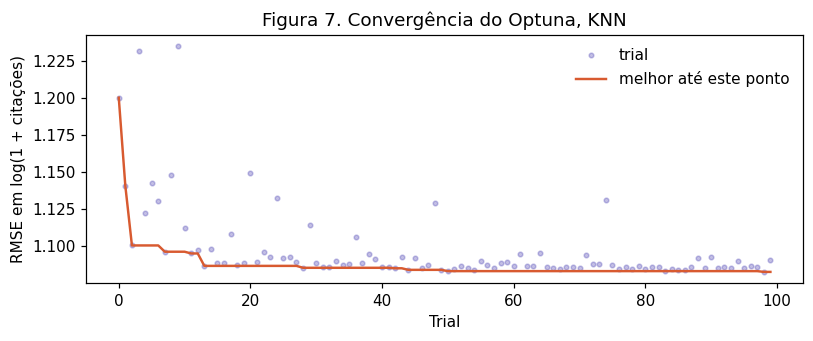

Hiperparâmetros vencedores:
  min_frequencia   65
  escala           standard
  n_neighbors      26
  weights          distance
  metric           manhattan


In [30]:
grafico_convergencia("knn", "Figura 7. Convergência do Optuna, KNN")
print("Hiperparâmetros vencedores:")
for chave, valor in resultados["knn"]["melhores_hiperparametros"].items():
    print(f"  {chave:16s} {valor}")


<div style="text-align: justify; max-width: 96%">

O &#119896;-NN foi o pior dos pipelines: RMSE de 1,0485 (desvio de 0,0234), MAE de 45,30 citações e Spearman de 0,493. Ele ainda supera a mediana com folga, mas fica claramente atrás do Rigde (0,9736). Isso é coerente com o que se esperava: depois da codificação, a matriz tem muitas colunas, e em alta dimensão as distâncias entre os artigos ficam parecidas, o que enfraquece a própria ideia de "vizinho mais próximo".

Os hiperparâmetros vencedores reforçam essa leitura de limitação do &#119896;-NN: a distância de Manhattan foi a favorecida, uma vez que soma as diferenças igualmente por dimensão, sendo menos dominada por uma única coluna com diferença grande do que a euclidiana; pesos por distância (`distance`), que dão mais voz aos vizinhos mais próximos; 18 vizinhos (um valor razoável); e um `min_frequencia` de 16, maior que o dos outros pipelines, isto é, menos colunas de revista e tópico (menos dimensões). Novamente, podemos observar que os primeiros trials foram os mais impactantes para a melhora de desempenho do modelo, havendo uma estabilização por volta do trial 25~30.

</div>

### 4.4. Floresta Aleatória

#### 4.4.1. O algoritmo

<div style="text-align: justify; max-width: 96%">

Antes da floresta, vale lembrar o que é uma árvore de decisão: um modelo que funciona como um fluxograma, dividindo os dados repetidamente por perguntas do tipo "o atributo X é maior que tal valor?" e prevendo, em cada folha, a média/moda (média para problemas de regressão - o caso tratado - e moda para os de classificação) dos exemplos que chegaram até ela (as árvores buscam delimitar justamente qual é conjunto de perguntas que vão dividir bem os dados para chegar numa conclusão verdadeira sobre eles). As árvores são flexíveis, mas uma árvore profunda sozinha decora os dados de treino com muita facilidade, geralmente apresentando baixo viés e alta variância.

> Se uma única árvore decora os dados, o que acontece quando se tira a média de muitas árvores diferentes?

A floresta aleatória responde a essa pergunta utilizadno um comitê de árvores treinadas em paralelo pela estratégia de *bagging*: cada árvore vê uma reamostragem com reposição dos exemplos e, em cada divisão, apenas um subconjunto sorteado dos atributos. A previsão final decorre de uma média das decisões de cada árvores, de modo que cada árvore decora os dados de uma maneira diferente e, por meio da aleatoriedade (tanto na amostragem dos exemplos quanto a dos atributos), se cancelam (majoritariamente) ao serem combinados.

Como as árvores não mudam com transformações monótonas (transformações que alteram a distribuição ou a escala, mas mantém a ordem original entre os dados) dos atributos, aqui não há padronização, e as categóricas recebem codificação ordinal em vez de indicadora, dessa forma evitando uma matriz muito larga.

</div>

#### 4.4.2. Hiperparâmetros e Optuna

<div style="text-align: justify; max-width: 96%">

Os intervalos escolhidos foram:

- `n_estimators`, o número de árvores, de 200 a 900. Abaixo de 200, a média ainda é instável; acima de 900, o ganho satura e só custa tempo, já que a floresta não sobreajusta com mais árvores, apenas para de melhorar;
- `max_depth` de 4 a 40, `min_samples_leaf` de 1 a 30 e `min_samples_split` de 2 a 40, que são os freios diretos do sobreajuste - o risco real com menos de quatro mil linhas e dezenas de atributos. Os dois últimos estão em escala logarítmica, porque a diferença entre 1 e 3 exemplos por folha importa muito mais do que entre 27 e 30;
- `max_features`, de 0,1 a 1,0, que controla a descorrelação descrita acima: em 1,0, todas as árvores veem todos os atributos em cada divisão e ficam parecidas, perdendo o benefício da média;
- `min_frequencia`, com a mesma faixa do &#119896;-NN.

</div>

<div style="text-align: justify; max-width: 96%">

O código segue o mesmo padrão, com duas diferenças em relação ao &#119896;-NN. O pré-processamento recebe `"nenhuma"` e `"ordinal"`: sem escala, pelo motivo já discutido, e com codificação ordinal, que transforma cada categoria em um número inteiro. 

</div>

In [31]:
from sklearn.ensemble import RandomForestRegressor


def espaco_rf(trial):
    return {
        "min_frequencia": trial.suggest_int("min_frequencia", 5, 400, log=True),
        "n_estimators": trial.suggest_int("n_estimators", 200, 900, step=100),
        "max_depth": trial.suggest_int("max_depth", 4, 40),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 30, log=True),
        "min_samples_split": trial.suggest_int("min_samples_split", 2, 40, log=True),
        "max_features": trial.suggest_float("max_features", 0.1, 1.0),
    }


def constroi_rf(p):
    return Pipeline([
        ("prep", preprocessamento(p["min_frequencia"], "nenhuma", "ordinal")),
        ("modelo", RandomForestRegressor(n_estimators=p["n_estimators"],
                                         max_depth=p["max_depth"],
                                         min_samples_leaf=p["min_samples_leaf"],
                                         min_samples_split=p["min_samples_split"],
                                         max_features=p["max_features"],
                                         random_state=SEMENTE, n_jobs = -1)),
    ])


resultados["random_forest"] = roda_otimizacao("random_forest", espaco_rf, constroi_rf)

[random_forest] resultado reaproveitado de saidas\melhores_modelos.json
  RMSE log  1.0386 (desvio entre dobras 0.0436)
  MAE       46.50 citações
  Spearman  0.523
  tempo     19.3 min


#### 4.4.3. Resultados

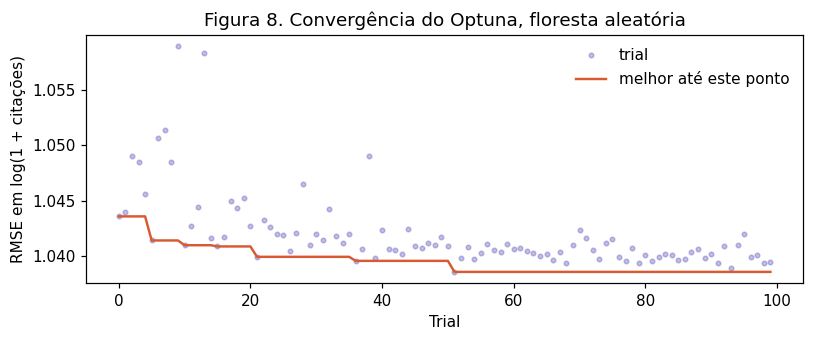

Hiperparâmetros vencedores:
  min_frequencia       9
  n_estimators         800
  max_depth            22
  min_samples_leaf     2
  min_samples_split    9
  max_features         0.31418041630211097


In [32]:
grafico_convergencia("random_forest", "Figura 8. Convergência do Optuna, floresta aleatória")

print("Hiperparâmetros vencedores:")
for chave, valor in resultados["random_forest"]["melhores_hiperparametros"].items():
    print(f"  {chave:20s} {valor}")


<div style="text-align: justify; max-width: 96%">

A floresta aleatória obteve RMSE de 0,9969 (desvio de 0,0270), MAE de 43,94 citações e Spearman de 0,545: melhor que o &#119896;-NN, mas ainda atrás do Rigde..

Os hiperparâmetros mostram uma floresta de árvores profundas (`max_depth` de 25) com folhas pequenas (`min_samples_leaf` de 2), isto é, árvores individuais de baixo viés, cuja variância é reduzida pela média e pelo sorteio de cerca de metade dos atributos em cada divisão (`max_features` de 0,528). O número de árvores terminou em 900, o limite superior da faixa, o que não preocupa muito: como discutido na escolha dos intervalos, mais árvores não fazem a floresta sobreajustar, apenas param de melhorar, de modo que um limite maior provavelmente só aumentaria o tempo. Pelo gráfico de convergência, o melhor valor foi atingido por volta do trial 25 e não mudou mais, com os trials seguintes concentrados logo acima dele - a superfície de busca da floresta é relativamente plana perto do ótimo.

</div>

### 4.5. XGBoost

#### 4.5.1. O algoritmo

<div style="text-align: justify; max-width: 96%">

O boosting inverte a lógica do bagging. Em vez de treinar árvores independentes e tirar a média, ele treina árvores em sequência, cada uma ajustada ao que as anteriores erraram. No *gradient boosting*, "o que as anteriores erraram" é o gradiente negativo da função de perda em relação à previsão atual. Assim, o processo se torna uma descida de gradiente no espaço das funções, e cada nova árvore dá um pequeno passo na direção que mais reduz o erro - e esse "passo" é chamado de taxa de aprendizado.

A diferença de regime em relação à floresta é o que vale reter: a floresta reduz a variância a partir de árvores profundas, de baixo viés; o boosting reduz o viés a partir de árvores rasas, de alto viés. O boosting costuma chegar mais longe, mas sobreajusta com muito mais facilidade - por isso seus hiperparâmetros funcionam como "freios" a essa alta variância que tende a surgir.

O XGBoost acrescenta ao algoritmo clássico termos de regularização L1 e L2 diretamente na função objetivo, uma condição de ganho mínimo para aceitar uma divisão, tratamento próprio de valores ausentes e um crescimento das árvores por histogramas, que o torna bem mais rápido.

**Observação: para o melhor entendimento do XGBoost, convém ler a Esfinge do Matheus Luiz, disponível na biblioteca real no *guthub*.**

</div>

#### 4.5.2. Hiperparâmetros e Optuna

<div style="text-align: justify; max-width: 96%">

Os intervalos escolhidos foram:

- `n_estimators` e `learning_rate` trocam entre si: mais árvores com passos menores chegam a um ajuste parecido com menos árvores de passos maiores. Por isso, a taxa de aprendizado vai de 0,005 a 0,3 (em escala logarítmica) e o número de árvores de 200 a 1500;
- `max_depth` vai de 1 a 10, bem mais raso que na floresta, porque o boosting funciona somando aprendizes fracos em sequência, e árvores profundas aqui sobreajustam facilmente;
- `min_child_weight` e `gamma` são os freios de complexidade - assim limitando a variância. O `min_child_weight` limita basicamente o número de exemplos exigidos nas divisões do split realizado. O `gamma` é o ganho mínimo para aceitar uma divisão. Todos estão em escala logarítmica, porque atuam em ordens de grandeza;
- `subsample` (de 0,5 a 1.0) e `colsample_bytree` (de 0,3 a 1,0) sorteiam exemplos e atributos para cada árvore, injetando a aleatoriedade que o boosting não tem por construção - um papel parecido com o do `max_features` na floresta, controlando a descorrelação entre as árvores criadas;
- `min_frequencia`, com a mesma faixa dos anteriores.

</div>

<div style="text-align: justify; max-width: 96%">

No código a seguir, duas escolhas valem atenção: `tree_method="hist"` usa o crescimento por histogramas, que discretiza os atributos contínuos em intervalos e torna o treino muito mais rápido, e `objective="reg:squarederror"` é o erro quadrático, coerente com o RMSE que o Optuna minimiza (otimizar uma coisa e avaliar outra seria um descuido comum) - essa otimização do tempo de busca foi realizada sob assistência de ferramentas de IA, para que o notebook não ficasse muito pesado para rodar.

</div>

In [33]:
from xgboost import XGBRegressor


def espaco_xgboost(trial):
    return {
        "min_frequencia": trial.suggest_int("min_frequencia", 5, 400, log=True),
        "n_estimators": trial.suggest_int("n_estimators", 200, 1500, step=100),
        "learning_rate": trial.suggest_float("learning_rate", 0.005, 0.3, log=True),
        "max_depth": trial.suggest_int("max_depth", 1, 10),
        "min_child_weight": trial.suggest_float("min_child_weight", 0.5, 30, log=True),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.3, 1.0),
        "gamma": trial.suggest_float("gamma", 1e-4, 5, log=True),
    }


def constroi_xgboost(p):
    return Pipeline([
        ("prep", preprocessamento(p["min_frequencia"], "nenhuma", "ordinal")),
        ("modelo", XGBRegressor(n_estimators=p["n_estimators"],
                                learning_rate=p["learning_rate"],
                                max_depth=p["max_depth"],
                                min_child_weight=p["min_child_weight"],
                                subsample=p["subsample"],
                                colsample_bytree=p["colsample_bytree"],
                                gamma=p["gamma"],
                                objective="reg:squarederror",
                                tree_method="hist", random_state=SEMENTE,
                                n_jobs=-1, verbosity=0)),
    ])


resultados["xgboost"] = roda_otimizacao("xgboost", espaco_xgboost, constroi_xgboost)

[xgboost] resultado reaproveitado de saidas\melhores_modelos.json
  RMSE log  1.0192 (desvio entre dobras 0.0459)
  MAE       45.90 citações
  Spearman  0.547
  tempo     14.6 min


#### 4.5.3. Resultados

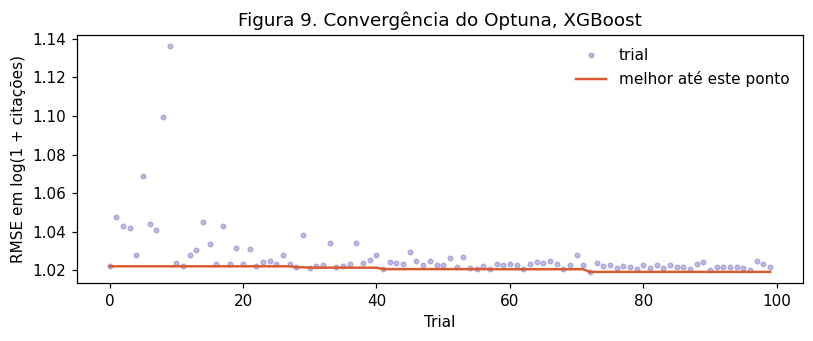

Hiperparâmetros vencedores:
  min_frequencia       7
  n_estimators         900
  learning_rate        0.01018
  max_depth            4
  min_child_weight     1.48237
  subsample            0.56297
  colsample_bytree     0.8628
  gamma                1.02517


In [34]:
grafico_convergencia("xgboost", "Figura 9. Convergência do Optuna, XGBoost")

print("Hiperparâmetros vencedores:")
for chave, valor in resultados["xgboost"]["melhores_hiperparametros"].items():
    valor = round(valor, 5) if isinstance(valor, float) else valor
    print(f"  {chave:20s} {valor}")

<div style="text-align: justify; max-width: 96%">

O XGBoost foi o melhor dos modelos de árvore: RMSE de 0,9771 (desvio de 0,0259), MAE de 43,59 citações e Spearman de 0,567. Ele empata, na prática, com o Rigde (0,9736): a diferença entre os dois é muito menor que o desvio entre as dobras, e o MAE é praticamente o mesmo.

Os hiperparâmetros seguem o padrão esperado da troca entre número de árvores e taxa de aprendizado: muitas árvores (1200) com passos pequenos (`learning_rate` de 0,01446). As árvores são rasas (`max_depth` de 4), o que limita as interações a poucos atributos por vez, e o `gamma` de 2,31811 exige uma redução de perda considerável para que uma divisão seja feita. O `subsample` de 0,5709 (perto do limite inferior de 0,5) e o `colsample_bytree` de 0,83032 acrescentam aleatoriedade, e o `min_frequencia` ficou de novo em 5, o limite inferior.

Através do gráfico de convergência, a busca melhorou gradualmente até por volta do trial 70, um comportamento diferente do Rigde (o que provavelmente ocorre porque o espaço de oito hiperparâmetros é muito maior).

</div>

### 4.6. Stacking

#### 4.6.1. O algoritmo

<div style="text-align: justify; max-width: 96%">

O empilhamento (*stacking*), combina os modelos anteriores (que são chamados de bases) por meio de um meta-modelo (o modelo que os combina), que aprende, a partir das previsões deles, como ponderá-las. A diferença em relação a uma média simples é que os pesos são aprendidos - e o meta-modelo pode, por exemplo, descobrir que uma base que é fraca sozinha ainda acrescenta algo às outras.

No entanto, existe um ponto delicado: como devem ser geradas as entradas para o meta-modelo sem que haja vazamento de dados? Veja que essas entradas serão as previsões dos modelos bases, mas caso bases preverem os mesmos dados com os quais foram treinadas, as previsões serão demasiadamente otimistas - e, por conseguinte, o meta-modelo vai favorecer a base que mais sobreajustou. 

Por isso, no lugar de uma separação de praxe em treino e teste, o stacking trabalha com três níveis de separação dos dados, cada um com uma função diferente:

- o **laço interno** gera as entradas do meta-modelo. Dentro da parte de treino, os dados são divididos em cinco dobras: cada base é treinada em quatro delas e prevê a quinta, até que todos os artigos tenham uma previsão vinda de um modelo que não os viu. São essas previsões que o meta-modelo usa para aprender os pesos (elas não tem contato com os dados do treino do meta-modelo, e, caso tivessem, ele seria muito otimista);

- o **"teste 1"** é a dobra externa da validação cruzada, usada para escolher os hiperparâmetros do meta-modelo. As bases são reajustadas na parte de treino inteira e preveem o teste 1, o meta-modelo combina essas previsões e mede-se o erro. Nem as bases nem o meta-modelo viram o teste 1 antes de prevê-lo. Vale notar que o teste 1 não é um conjunto à parte: ele é uma das cinco dobras do treino, exatamente como as dobras de validação usadas pelos outros pipelines, e que o processo inteiro se repete cinco vezes, uma para cada dobra;

- o **"teste 2"** é o conjunto de teste propriamente dito, separado no começo do trabalho. Ele não participa de nada nem no treino do modelo e nem na otimização dos hiperparâmetros, só sendo é aberto para a avaliação final do stacking e de todos os outros modelos.

Assim, o laço interno fica dentro do treino, o teste 1 fica fora do laço interno (mas ainda dentro do treino) e o teste 2 fica fora de tudo.
</div>

#### 4.6.2. Hiperparâmetros e Optuna

<div style="text-align: justify; max-width: 96%">

O meta-modelo combina os modelos observados por meio de um Rigde, uma vez que suas entradas são as previsões das bases para o mesmo alvo, portanto muito parecidas entre si, e um meta-modelo complexo sobreajustaria essas poucas colunas sem ganho real (a penalização L2 do Rigde é o que mantém os pesos estáveis diante dessa correlação que tendem a apresentam). Os hiperparâmetros a serem otimizados são:

- `alpha`, de 0.001 a 1000 em escala logarítmica, a força da regularização. A faixa é larga de propósito: com tão poucas colunas, o valor ótimo pode estar em qualquer ordem de grandeza - e é difícil justificar um intervalo arbitrário -, dependendo de quão parecidas forem as bases;
- `fit_intercept`, que decide se o meta-modelo pode somar uma constante, corrigindo um viés comum a todas as bases;
- `positive`, que restringe os pesos a valores não negativos. Vale testar, pois um peso negativo significa que o meta-modelo usa uma base "ao contrário", o que às vezes ajuda e às vezes é sinal de sobreajuste;
- `comite`, um hiperparâmetro de seleção que decide quais bases entram na combinação - cabe destacar que não há conjuntos vazios. Esse hiperparâmetro existe porque bases muito parecidas entre si podem somar menos que um subconjunto delas, e deixar o Optuna decidir é mais honesto do que escolher à mão (basicamente, com as informações disponíveis, é insustentável fazer uma seleção específica).

</div>

<div style="text-align: justify; max-width: 96%">

A linha que mais importa é `modelo.fit(X_parte.iloc[interno_treino], ...)`: ela é o laço interno, e as bases não são fitadas com o teste 1, já que `X_parte` contém apenas uma porção da parte de treino das bases. Logo depois, cada base é reajustada em `X_parte` inteiro e prevê o teste 1, e são essas previsões que o meta-modelo combina na avaliação de cada trial.
</div>

In [35]:
BASES = ["rigde", "knn", "random_forest", "xgboost"]
UTILIZADOS = {"rigde": constroi_rigde, "knn": constroi_knn,
              "random_forest": constroi_rf, "xgboost": constroi_xgboost}
CACHE_META = os.path.join(SAIDAS, "meta_matrizes.csv")


def matrizes_aninhadas(recalcular=False):
    """
    por dobra externa "ext", devolve:
      meta_treino[ext]    previsões do laço INTERNO, na parte de treino de ext
      meta_validacao[ext] previsões das bases reajustadas, na dobra ext
    """
    if os.path.exists(CACHE_META) and not recalcular:
        guardado = pd.read_csv(CACHE_META, float_precision="round_trip")
        # o cache só vale se foi feito com as mesmas bases (uma coluna por base)
        if [c for c in guardado.columns if c not in ("dobra", "parte", "indice")] == BASES:
            print(f"Matrizes do meta-modelo reaproveitadas de {CACHE_META}")
            meta_treino, meta_validacao, indices = [], [], []
            for ext in range(1, N_DOBRAS + 1):
                da_dobra = guardado[guardado["dobra"] == ext]
                treino = da_dobra[da_dobra["parte"] == "treino"]
                validacao = da_dobra[da_dobra["parte"] == "validacao"]
                meta_treino.append(treino[BASES].to_numpy())
                meta_validacao.append(validacao[BASES].to_numpy())
                indices.append((treino["indice"].to_numpy(), validacao["indice"].to_numpy()))
            return meta_treino, meta_validacao, indices

    parametros = {nome: resultados[nome]["melhores_hiperparametros"] for nome in BASES}
    meta_treino, meta_validacao, indices = [], [], []
    inicio = time.time()

    for ext, (treino_idx, validacao_idx) in enumerate(PARTICOES, start=1):
        X_parte = X_treino.iloc[treino_idx]
        z_parte = z_treino[treino_idx]

        internas = list(KFold(n_splits=N_DOBRAS, shuffle=True, random_state=SEMENTE)
                        .split(np.arange(len(treino_idx))))

        bloco_treino = np.zeros((len(treino_idx), len(BASES)))
        bloco_validacao = np.zeros((len(validacao_idx), len(BASES)))

        for coluna, nome in enumerate(BASES):
            for interno_treino, interno_validacao in internas:
                modelo = UTILIZADOS[nome](parametros[nome])
                modelo.fit(X_parte.iloc[interno_treino], z_parte[interno_treino])
                bloco_treino[interno_validacao, coluna] = modelo.predict(
                    X_parte.iloc[interno_validacao])
            # reajuste na parte de treino inteira, para prever a dobra externa.
            modelo = UTILIZADOS[nome](parametros[nome])
            modelo.fit(X_parte, z_parte)
            bloco_validacao[:, coluna] = modelo.predict(X_treino.iloc[validacao_idx])

        meta_treino.append(bloco_treino)
        meta_validacao.append(bloco_validacao)
        indices.append((treino_idx, validacao_idx))
        print(f"  dobra externa {ext}/{N_DOBRAS} pronta ({(time.time()-inicio)/60:.1f} min)")

    # um CSV "comprido": uma linha por artigo, por dobra externa e por parte
    # (treino ou validação), com uma coluna de previsão para cada base
    pedacos = []
    for ext, (bloco_treino, bloco_validacao, (treino_idx, validacao_idx)) in enumerate(
            zip(meta_treino, meta_validacao, indices), start=1):
        for parte, bloco, idx in (("treino", bloco_treino, treino_idx),
                                  ("validacao", bloco_validacao, validacao_idx)):
            pedaco = pd.DataFrame(bloco, columns=BASES)
            pedaco.insert(0, "indice", idx)
            pedaco.insert(0, "parte", parte)
            pedaco.insert(0, "dobra", ext)
            pedacos.append(pedaco)
    pd.concat(pedacos, ignore_index=True).to_csv(CACHE_META, index=False)
    return meta_treino, meta_validacao, indices


print(f"Montando as matrizes aninhadas ({len(BASES) * N_DOBRAS * (N_DOBRAS + 1)} ajustes na primeira execução):")
META_TREINO, META_VALIDACAO, META_INDICES = matrizes_aninhadas()
print(f"\nmatrizes prontas: {len(META_TREINO)} dobras externas, {len(BASES)} bases")

Montando as matrizes aninhadas (120 ajustes na primeira execução):
Matrizes do meta-modelo reaproveitadas de saidas\meta_matrizes.csv

matrizes prontas: 5 dobras externas, 4 bases


<div style="text-align: justify; max-width: 96%">

Com as matrizes prontas, o meta-modelo fica barato: cada trial é só cinco ajustes de um Rigde sobre poucas colunas.

</div>

In [36]:

from itertools import combinations

COMITES = [",".join(c) for tamanho in range(1, len(BASES) + 1)
           for c in combinations(BASES, tamanho)]
# print(f"Comitês possíveis: {len(COMITES)}")
# for comite in COMITES:
#     print(f"  {comite}")


def avalia_meta(parametros):
    """Roda o meta-modelo nas matrizes aninhadas e devolve as previsões."""
    usadas = [BASES.index(nome) for nome in parametros["comite"].split(",")]
    previsoes = np.zeros(len(z_treino))
    rmses = []
    for bloco_treino, bloco_validacao, (treino_idx, validacao_idx) in zip(
            META_TREINO, META_VALIDACAO, META_INDICES):
        meta = Ridge(alpha=parametros["alpha"],
                     fit_intercept=parametros["fit_intercept"],
                     positive=parametros["positive"],
                     solver="lbfgs" if parametros["positive"] else "auto")
        # o `solver="lbfgs"` é necessário quando `positive=True` - restrição padrão do Rigde 
        meta.fit(bloco_treino[:, usadas], z_treino[treino_idx])
        p = meta.predict(bloco_validacao[:, usadas])
        previsoes[validacao_idx] = p
        rmses.append(rmse_log(z_treino[validacao_idx], p))
    return previsoes, np.array(rmses), usadas


def otimiza_stacking(n_trials=N_TRIALS, recalcular=False):
    melhores = le_melhores()
    # só reaproveita se o stacking guardado foi feito com as mesmas bases
    if (not recalcular and "stacking" in melhores
            and melhores["stacking"].get("bases_disponiveis") == BASES):
        print(f"[stacking] resultado reaproveitado de {ARQUIVO_MELHORES}")
        mostra_resultado(melhores["stacking"])
        return melhores["stacking"]

    import optuna
    optuna.logging.set_verbosity(optuna.logging.WARNING)
    inicio = time.time()

    def objetivo(trial):
        parametros = {
            "alpha": trial.suggest_float("alpha", 1e-3, 1e3, log=True),
            "fit_intercept": trial.suggest_categorical("fit_intercept", [True, False]),
            "positive": trial.suggest_categorical("positive", [True, False]),
            "comite": trial.suggest_categorical("comite", COMITES),
        }
        return float(avalia_meta(parametros)[1].mean())

    estudo = optuna.create_study(direction="minimize",
                                 sampler=optuna.samplers.TPESampler(seed=SEMENTE),
                                 study_name="stacking")
    estudo.optimize(objetivo, n_trials=n_trials, show_progress_bar=False)

    previsoes, rmses, usadas = avalia_meta(estudo.best_params)
    guarda_historico("stacking", estudo.trials_dataframe())
    registro = guarda_resultado("stacking", estudo.best_params, rmses, previsoes, n_trials,
                        time.time() - inicio,
                        extra={"bases_no_comite": [BASES[i] for i in usadas],
                               "bases_disponiveis": BASES})
    print(f"\n[stacking] {n_trials} trials concluídos")
    mostra_resultado(registro)
    return registro


resultados["stacking"] = otimiza_stacking()

[stacking] resultado reaproveitado de saidas\melhores_modelos.json
  RMSE log  1.0011 (desvio entre dobras 0.0420)
  MAE       45.54 citações
  Spearman  0.570
  tempo     0.0 min


#### 4.6.3. Resultados

Bases escolhidas pelo Optuna: rigde, xgboost

Hiperparâmetros vencedores:
  alpha              0.00101
  fit_intercept      True
  positive           False
  comite             rigde,xgboost


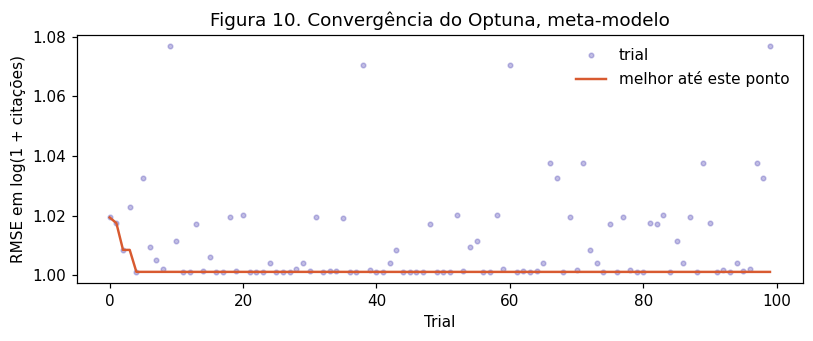

In [37]:
print("Bases escolhidas pelo Optuna:", ", ".join(resultados["stacking"]["bases_no_comite"]))
print("\nHiperparâmetros vencedores:")
for chave, valor in resultados["stacking"]["melhores_hiperparametros"].items():
    valor = round(valor, 5) if isinstance(valor, float) else valor
    print(f"  {chave:18s} {valor}")

grafico_convergencia("stacking", "Figura 10. Convergência do Optuna, meta-modelo")

<div style="text-align: justify; max-width: 96%">

O stacking obteve o menor RMSE da validação cruzada: 0,9605 (desvio de 0,0314), com MAE de 43,09 citações e Spearman de 0,588, contra 0,9736, 43,60 e 0,576 do Rigde. O ganho existe, mas é pequeno, bem menor que o desvio entre as dobras. O Optuna escolheu o comitê completo (as quatro bases), com `positive=True` (nenhum peso negativo), e com um `alpha` de 2,35729. A figura acima revelou que o meta-modelo convergiu rápido, por volta do trial 20, o que é esperado para um espaço de busca tão pequeno.

</div>

## 5. Comparando os modelos

<div style="text-align: justify; max-width: 96%">

Esta seção é a única que abre o conjunto de teste (o teste 2). Para aumentar a robustez da comparação, utiliza-se o **bootstrap**: sorteiam-se 967 linhas com reposição, calcula-se a métrica e repete-se o processo duas mil vezes (como são usados poucos artigos, a análise é limitada pelos percentis 2,5 e 97,5, dando um intervalo de 95% de confiança) - porém, quando é feita essa reamostra, é necessário que os modelos sejam comparados de acordo com o conjunto daquela reamostra (a comparação deve ser pareada), de forma que a diferença de desempenho possa ser atribuída realmente aos modelos e não aos exemplos sorteados

</div>

<div style="text-align: justify; max-width: 96%">

Primeiramente, o ajuste final. Cada modelo é reconstruído com os hiperparâmetros vencedores, ajustado no treino inteiro (e não em uma dobra, já que, com a escolha feita, não há razão para desperdiçar um quinto dos dados) e usado para prever o teste. A tabela acumula as métricas de validação cruzada, vindas do dicionário `resultados`, lado a lado com as de teste - caso houvesse uma diferença grande, isso sugeriria que a escolha de hiperparâmetros se ajustou demais às dobras específicas.

</div>

In [38]:

MODELOS = ["baseline_mediana", "rigde", "knn",
           "random_forest", "xgboost"]
UTILIZADOS_TESTE = {"rigde": constroi_rigde, "knn": constroi_knn,
                    "random_forest": constroi_rf, "xgboost": constroi_xgboost}
# é definido um novo dicionário apenas para não alterar a memória das escolhas previamente feitas
BASELINES = {"baseline_mediana": baseline_mediana}

previsoes_teste = {}    # nome do modelo -> previsões no teste, em log
modelos_finais = {}     # nome do modelo -> modelo já ajustado no treino inteiro
linhas_da_tabela = []


def linha_da_tabela(nome, z_previsto):
    """Junta as métricas da validação cruzada e as do teste em uma linha só."""
    no_teste = todas_as_metricas(z_teste, z_previsto)
    return {
        "modelo": nome,
        "rmse_cv": resultados[nome]["rmse_log_medio"],
        "desvio_cv": resultados[nome]["rmse_log_desvio"],
        "mae_cv": resultados[nome]["metricas"]["mae_real"],
        "spearman_cv": resultados[nome]["metricas"]["spearman"],
        "rmse_teste": no_teste["rmse_log"],
        "mae_teste": no_teste["mae_real"],
        "spearman_teste": no_teste["spearman"],
    }


for nome in MODELOS:
    if nome in BASELINES:
        modelo = BASELINES[nome]()
    else:
        modelo = UTILIZADOS_TESTE[nome](resultados[nome]["melhores_hiperparametros"])
    modelo.fit(X_treino, z_treino)      # agora sim, no treino inteiro
    z_previsto = modelo.predict(X_teste)

    previsoes_teste[nome] = z_previsto
    modelos_finais[nome] = modelo
    linhas_da_tabela.append(linha_da_tabela(nome, z_previsto))
    print(f"  {nome:18s} RMSE teste {linhas_da_tabela[-1]['rmse_teste']:.4f}")

  baseline_mediana   RMSE teste 1.2363
  rigde              RMSE teste 1.0511
  knn                RMSE teste 1.1156
  random_forest      RMSE teste 1.0741
  xgboost            RMSE teste 1.0566


<div style="text-align: justify; max-width: 96%">

O stacking precisa de um tratamento à parte, porque não é um único `Pipeline` propriamente dito. Aqui, o processo de separação em três partes se repete sobre o treino inteiro, e o papel que era do teste 1 passa a ser do teste 2. Para prever o teste 2, são necessárias duas coisas: as entradas do meta-modelo no treino, que vêm de um laço interno de cinco dobras sobre todos os artigos do treino, e as entradas no teste 2, que vêm das bases já ajustadas no treino inteiro. Nesta etapa não existe teste 1, já que os hiperparâmetros já foram escolhidos e não há mais nada a validar dentro do treino.

Como consequência, o código monta a previsão do stacking em três passos: o laço interno gera as entradas do meta-modelo no treino, o meta-modelo é ajustado nelas, e, por fim, cada base (já ajustada na célula anterior) prevê o teste 2, essas previsões viram as colunas de entrada e o meta-modelo as combina. Os pesos impressos ao final são os coeficientes do Rigde que faz o papel de meta-modelo e podem ser interpretados como "o quanto cada base contribuiu para a previsão combinada".

</div>

In [39]:
registro_stacking = resultados["stacking"]
bases_usadas = registro_stacking["bases_no_comite"]
hiper_meta = registro_stacking["melhores_hiperparametros"]

dobrinhas = list(KFold(n_splits=N_DOBRAS, shuffle=True, random_state=SEMENTE)
                 .split(np.arange(len(z_treino))))
entradas_meta = np.zeros((len(z_treino), len(bases_usadas)))

for coluna, nome in enumerate(bases_usadas):
    hiper_base = resultados[nome]["melhores_hiperparametros"]
    for interno_treino, interno_validacao in dobrinhas:
        modelo = UTILIZADOS_TESTE[nome](hiper_base)
        modelo.fit(X_treino.iloc[interno_treino], z_treino[interno_treino])
        entradas_meta[interno_validacao, coluna] = modelo.predict(
            X_treino.iloc[interno_validacao])

meta_final = Ridge(alpha=hiper_meta["alpha"],
                   fit_intercept=hiper_meta["fit_intercept"],
                   positive=hiper_meta["positive"],
                   solver="lbfgs" if hiper_meta["positive"] else "auto")
meta_final.fit(entradas_meta, z_treino)

# cada base prevê o teste 2, e as previsões viram as colunas do meta-modelo
entradas_teste = np.column_stack([modelos_finais[nome].predict(X_teste)
                                  for nome in bases_usadas])
previsoes_teste["stacking"] = meta_final.predict(entradas_teste)
linhas_da_tabela.append(linha_da_tabela("stacking", previsoes_teste["stacking"]))

print(f"  {'stacking':18s} -> RMSE teste {linhas_da_tabela[-1]['rmse_teste']:.4f}")
print("\nPesos do meta-modelo:")
for nome, peso in zip(bases_usadas, meta_final.coef_):
    print(f"  {nome:16s} {peso:+.3f}")

  stacking           -> RMSE teste 1.0400

Pesos do meta-modelo:
  rigde            +0.588
  xgboost          +0.459


<div style="text-align: justify; max-width: 96%">

Vejamos, portanto, a tabela consolidada, ordenada pelo RMSE de teste:
</div>

In [40]:
tabela = (pd.DataFrame(linhas_da_tabela)
          .sort_values("rmse_teste").reset_index(drop=True))
tabela.to_csv(os.path.join(SAIDAS, "tabela_consolidada.csv"), index=False)
display(tabela.style.format({
    # style format controla as casas decimais
    "rmse_cv": "{:.4f}", "desvio_cv": "{:.4f}", "mae_cv": "{:.2f}",
    "spearman_cv": "{:.3f}", "rmse_teste": "{:.4f}", "mae_teste": "{:.2f}",
    "spearman_teste": "{:.3f}"}).hide(axis="index"))
    # hide esconde os indícies

modelo,rmse_cv,desvio_cv,mae_cv,spearman_cv,rmse_teste,mae_teste,spearman_teste
stacking,1.0011,0.0420,45.54,0.570,1.0400,142.94,0.549
rigde,1.0117,0.0370,46.62,0.560,1.0511,144.79,0.535
xgboost,1.0192,0.0459,45.90,0.547,1.0566,143.61,0.527
random_forest,1.0386,0.0436,46.50,0.523,1.0741,144.16,0.503
knn,1.0828,0.0436,47.39,0.476,1.1156,145.13,0.476
baseline_mediana,1.2152,0.0371,50.39,-0.018,1.2363,147.91,0.000


<div style="text-align: justify; max-width: 96%">

A ordem dos modelos pelo RMSE é a mesma na validação cruzada e no teste: stacking, Rigde, XGBoost, floresta aleatória, &#119896;-NN e mediana. Pelo MAE, o XGBoost fica ligeiramente à frente do Rigde nos dois casos (43,59 contra 43,60 na validação e 44,34 contra 44,66 no teste), e a melhora mais clara de todos os pipelines está na ordenação: o Spearman do stacking no teste é de 0,602, contra 0 da mediana, enquanto o MAE cai de 49,45 para 44,11 citações.

Todos os modelos pioram da validação cruzada para o teste (o stacking, por exemplo, vai de 0,9605 para 1,0059), mas a mediana, que não tem nenhum hiperparâmetro para se ajustar às dobras, piora de forma parecida (de 1,1936 para 1,2516), o que é um indício de que o conjunto de teste é simplesmente um pouco mais difícil que as dobras de validação, e não que a otimização tenha se ajustado demais a elas.

Por último, a contribuição de cada modelo: o Rigde tem o maior peso (+0,541), seguido pelo XGBoost (+0,315), e o &#119896;-NN (+0,133) e a floresta (+0,127) recebem pesos parecidos. É curioso que o &#119896;-NN, o pior modelo isolado, receba praticamente o mesmo peso que a floresta: o que importa no comitê não é só o desempenho de cada base, mas o quanto seus erros são diferentes dos erros das outras, assim uma hipótese plausível é a de que a floresta e o XGBoost, ambos de árvores, tendem a errar nos mesmos artigos, enquanto o &#119896;-NN erra de outra forma - justamente o tipo de aprendizado que o empilhamento oferece.

</div>

In [41]:
N_BOOTSTRAP = 2000

sorteador = np.random.default_rng(SEMENTE)
SORTEIOS = sorteador.integers(0, len(z_teste), size=(N_BOOTSTRAP, len(z_teste)))

distribuicoes = {}
for nome, z_previsto in previsoes_teste.items():
    acumulado = {"rmse_log": [], "mae_real": [], "spearman": []}
    for linhas in SORTEIOS:
        for chave, valor in todas_as_metricas(z_teste[linhas], z_previsto[linhas]).items():
            acumulado[chave].append(valor)
    distribuicoes[nome] = {chave: np.array(valores) for chave, valores in acumulado.items()}

intervalos = {}
for nome, metricas in distribuicoes.items():
    no_teste = todas_as_metricas(z_teste, previsoes_teste[nome])
    intervalos[nome] = {
        chave: {"estimativa": float(no_teste[chave]),
                "ic95_inferior": float(np.percentile(valores, 2.5)),
                "ic95_superior": float(np.percentile(valores, 97.5))}
        for chave, valores in metricas.items()}
    ic = intervalos[nome]["rmse_log"]
    print(f"  {nome:18s} RMSE {ic['estimativa']:.4f} "
          f"[{ic['ic95_inferior']:.4f}, {ic['ic95_superior']:.4f}]")

with open(os.path.join(SAIDAS, "intervalos.json"), "w", encoding="utf-8") as arquivo:
    json.dump(intervalos, arquivo, ensure_ascii=False, indent=2)

  baseline_mediana   RMSE 1.2363 [1.1561, 1.3191]
  rigde              RMSE 1.0511 [0.9690, 1.1536]
  knn                RMSE 1.1156 [1.0382, 1.2051]
  random_forest      RMSE 1.0741 [0.9934, 1.1655]
  xgboost            RMSE 1.0566 [0.9756, 1.1477]
  stacking           RMSE 1.0400 [0.9588, 1.1364]


In [42]:
comparacoes = []
for referencia in ("baseline_mediana", "rigde"):
    for nome in distribuicoes:
        if nome == referencia:
            continue
        diferenca = distribuicoes[nome]["rmse_log"] - distribuicoes[referencia]["rmse_log"]
        comparacoes.append({
            "modelo": nome,
            "referencia": referencia,
            "diferenca_media": float(diferenca.mean()),
            "ic95_inferior": float(np.percentile(diferenca, 2.5)),
            "ic95_superior": float(np.percentile(diferenca, 97.5)),
            "fracao_pior": float((diferenca > 0).mean()),
        })

comparacao_df = pd.DataFrame(comparacoes)
comparacao_df.to_csv(os.path.join(SAIDAS, "comparacao_pareada.csv"), index=False)

for referencia, apelido in (("rigde", "o Rigde"), ("baseline_mediana", "a mediana")):
    print(f"Diferença de RMSE contra {apelido}. Valor negativo = o modelo é melhor.\n")
    for c in comparacoes:
        if c["referencia"] == referencia:
            print(f"  {c['modelo']:18s} {c['diferenca_media']:+.4f} "
                  f"[{c['ic95_inferior']:+.4f}, {c['ic95_superior']:+.4f}]  "
                  f"pior em {100*c['fracao_pior']:5.1f}% dos sorteios")
    print()

Diferença de RMSE contra o Rigde. Valor negativo = o modelo é melhor.

  baseline_mediana   +0.1848 [+0.1398, +0.2317]  pior em 100.0% dos sorteios
  knn                +0.0645 [+0.0339, +0.0978]  pior em 100.0% dos sorteios
  random_forest      +0.0224 [-0.0022, +0.0484]  pior em  96.0% dos sorteios
  xgboost            +0.0051 [-0.0174, +0.0300]  pior em  65.9% dos sorteios
  stacking           -0.0112 [-0.0211, -0.0009]  pior em   1.7% dos sorteios

Diferença de RMSE contra a mediana. Valor negativo = o modelo é melhor.

  rigde              -0.1848 [-0.2317, -0.1398]  pior em   0.0% dos sorteios
  knn                -0.1203 [-0.1481, -0.0930]  pior em   0.0% dos sorteios
  random_forest      -0.1624 [-0.1975, -0.1260]  pior em   0.0% dos sorteios
  xgboost            -0.1797 [-0.2194, -0.1394]  pior em   0.0% dos sorteios
  stacking           -0.1961 [-0.2407, -0.1514]  pior em   0.0% dos sorteios



<div style="text-align: justify; max-width: 96%">

Os intervalos de 95% de cada modelo, isoladamente, têm cerca de um décimo de largura e se sobrepõem bastante entre os três melhores (stacking [0,9547; 1,0565], Rigde [0,9565; 1,0577] e XGBoost [0,9749; 1,0778]), de modo que, olhando só para eles, não seria possível ordená-los. A comparação pareada resolve parte da dúvida, já que mede a diferença entre dois modelos nos mesmos artigos sorteados:

- contra a mediana, todos os pipelines são melhores em 100% dos sorteios (o Rigde, por exemplo, reduz o RMSE em 0,2446, com intervalo de [-0,2855; -0,2013]), isto é, todos aprenderam alguma coisa;
- contra o Rigde, o &#119896;-NN (+0,0904) e a floresta (+0,0580) são piores em todos os sorteios, com intervalos inteiramente acima de zero: a complexidade adicional, nesses casos, não se pagou;
- o XGBoost é pior que o Rigde em 96,7% dos sorteios, com intervalo de [-0,0012; +0,0391], que inclui o zero por muito pouco - há uma indicação de que ele é pior, mas não uma certeza ao nível de 95% que definimos anteriormente;
- o stacking é pior que o Rigde em 30,8% dos sorteios (e melhor nos demais), com intervalo de [-0,0119; +0,0074], praticamente centrado em zero. Ou seja, a vantagem do stacking na tabela não é distinguível do acaso.

A conclusão mais honesta, portanto, é que o stacking e o Rigde empatam no teste, e que, portanto, nenhum dos modelos mais complexos superou, de forma clara, o modelo linear regularizado.

</div>

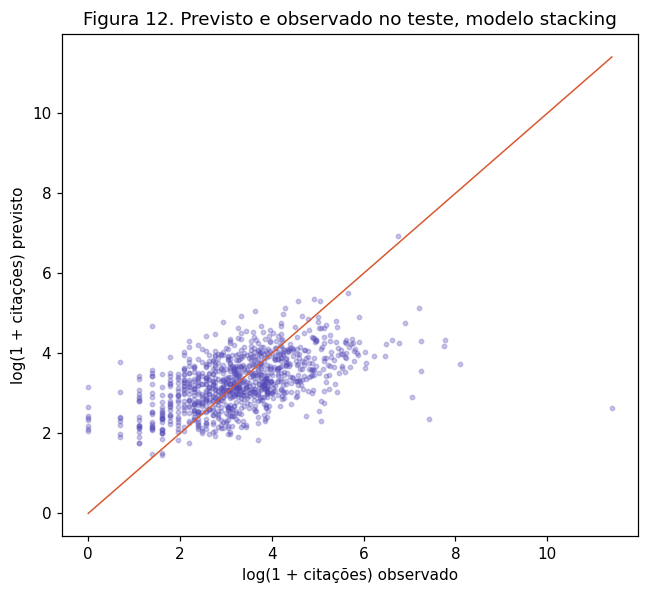

Melhor modelo pelo RMSE de teste: stacking


In [43]:
melhor = tabela.iloc[0]["modelo"]
z_melhor = previsoes_teste[melhor]

plt.figure(figsize=(6, 5.5))
plt.scatter(z_teste, z_melhor, s=8, alpha=0.3, color=roxin)
limites = [min(z_teste.min(), z_melhor.min()), max(z_teste.max(), z_melhor.max())]
plt.plot(limites, limites, color=laranjin, linewidth=1)   # a previsão perfeita
plt.xlabel("log(1 + citações) observado")
plt.ylabel("log(1 + citações) previsto")
plt.title(f"Figura 12. Previsto e observado no teste, modelo {melhor}")
figura("12_previsto_observado.png")

print(f"Melhor modelo pelo RMSE de teste: {melhor}")

<div style="text-align: justify; max-width: 96%">

Esse gráfico demonstra como o melhor modelo tende a realizar suas previsões: elas ficam comprimidas em uma faixa bem mais estreita que a dos valores observados, de maneira que os artigos pouco citados (à esquerda) são superestimados, e os muito citados (à direita) são subestimados - nenhum artigo do teste recebe uma previsão acima de cerca de 6 na escala logarítmica, enquanto os valores observados chegam a 8. Esse padrão permite estimar que, sem informação suficiente para identificar quais artigos serão excepcionais, o modelo prevê valores próximos do centro, que minimizam o erro quadrático. Os artigos sem nenhuma citação (a coluna em zero) são um bom exemplo: o modelo prevê para eles valores entre 1 e 3, aproximadamente, isto é, não consegue distingui-los dos artigos pouco citados.

</div>

## 6. Conclusões

<div style="text-align: justify; max-width: 96%">

O trabalho mostrou que é possível prever, em parte, o impacto de artigos de inteligência artificial usando apenas informações disponíveis na publicação, mas que esse poder de previsão é limitado. No conjunto de teste, o melhor modelo (o stacking) obteve RMSE de 1,0059 na escala logarítmica, contra 1,2516 da mediana, e uma correlação de Spearman de 0,602 entre as citações previstas e as observadas. Colocando em outras palavras, o modelo ordena os artigos razoavelmente bem, mas erra bastante o valor de cada um, em especial nos extremos, pois o MAE de 44,11 citações é alto perto da mediana de 26 citações do treino, e a gráfico comparando o previsto e o observado mostra que os artigos excepcionais continuam imprevisíveis.

O resultado mais importante, contudo, é o empate entre o stacking e o Rigde: a comparação pareada não encontrou diferença distinguível do acaso entre os dois, o que significa que, para estes atributos e este tamanho de amostra, um modelo linear regularizado já extrai praticamente toda a informação disponível. Ganhos maiores dependeriam, provavelmente, de atributos mais informativos, e não de algoritmos mais sofisticados. Entre os atributos analisados, a idade do artigo foi o mais associado ao alvo (correlação de postos de 0,388), seguida pelo número de referências (0,273), enquanto todas as demais associações foram fracas. Isso não quer dizer que algum desses atributos cause citações, apenas que, entre os artigos desta amostra, eles carregam informação sobre o alvo.

</div>

<div style="text-align: justify; max-width: 96%">

O trabalho tem, também, limitações claras. As citações são uma fotografia de uma única data e continuam se acumulando. A amostra cobre apenas artigos em inglês, com resumo e indexados no PubMed. O texto do título e do resumo entra no modelo apenas por contagens (número de palavras, tamanho médio da palavra, presença de dois-pontos), sem nenhuma leitura do conteúdo. A limitação mais importante, porém, diz respeito à idade. Como discutido na limpeza, ela entra no modelo como um controle do tempo de exposição (e, no uso real, como o horizonte da previsão), mas ela também é o atributo mais associado ao alvo, de modo que é provável que parte do desempenho venha simplesmente de saber há quanto tempo o artigo foi publicado, e não de algo sobre o artigo em si.

Como possíveis aperfeiçoamentos futuros, seria interessante utilizar algum tipo de processamento de linguagem natural (assim obtendo atributos mais descritivos do artigo de fato) - ferramenta, que, até o momento atual, ainda não foi aprendida pelo autor; incluir o histórico de citações dos autores antes da publicação, que é uma informação pré-publicação legítima e possivelmente mais informativa que a simples contagem de autores; testar um alvo normalizado pelo tempo, como citações por ano, que talvez separaria o efeito da idade do resto; e permitir que o Optuna controle uma etapa de redução de dimensionalidade ou de seleção de atributos.

</div>

## 7. Descrição do uso de IA neste trabalho

<div style="text-align: justify; max-width: 96%">

Ferramentas de inteligência artificial (em particular, chatbots) foram utilizadas neste trabalho nos seguintes pontos:

- **auxílio na organização dos dados $\to$** o código das funções de coleta pelas APIs do PubMed e da OpenAlex  foi escrito com forte assistência de IA, porém a partir das decisões de desenho tomadas pelo autor (as fontes, o termo de busca, a amostragem por janelas mensais e o casamento apenas por identificador exato); além disso, a ideia autoral de criar pastas e arquivos para organizar e guardar os dados obtidos sem que fosse necessário rodar toda a busca e otimização do zero foi realizada sob intenso suporte de ferramentas de IA

- **estudo $\to$** a IA foi usada como tutora, explicando o raciocínio por trás de cada etapa para que eu pudesse entendê-lo e realizá-lo autoralmente, além de ter fornecido referências para consulta, assim possibilitando aumentar a robustez teórica do projeto;

- **gráficos e imagens $\to$** eu pensei na estrutura das figuras (tanto gráficos quanto outras imagens) e mandei minha idealização para que a IA fornecesse os códigos que criam a figura de fato. 

</div>

## 8. Referências

<h4> Materiais da disciplina</h4>
<ul>
<li>CASSAR, D. R. <i>Aprendizado de máquina, k-NN e métricas</i>. Campinas: Ilum Escola de Ciência, 2026. Notebook Jupyter da disciplina ATP-203 - Aprendizado de Máquina (aula 2.1).</li>
<li>CASSAR, D. R. <i>Árvore de decisão e floresta aleatória</i>. Campinas: Ilum Escola de Ciência, 2026. Notebook Jupyter da disciplina ATP-203 - Aprendizado de Máquina (aula 4.0).</li>
<li>CASSAR, D. R. <i>Dados sintéticos e pipeline</i>. Campinas: Ilum Escola de Ciência, 2026. Notebook Jupyter da disciplina ATP-203 - Aprendizado de Máquina (aula 7.0).</li>
<li>CASSAR, D. R. <i>Divisão de dados em treino e teste</i>. Campinas: Ilum Escola de Ciência, 2026. Notebook Jupyter da disciplina ATP-203 - Aprendizado de Máquina (aula 2.2).</li>
<li>CASSAR, D. R. <i>Modelo linear e baseline</i>. Campinas: Ilum Escola de Ciência, 2026. Notebook Jupyter da disciplina ATP-203 - Aprendizado de Máquina (aula 3.0).</li>
<li>CASSAR, D. R. <i>Otimização de hiperparâmetros com optuna</i>. Campinas: Ilum Escola de Ciência, 2026. Notebook Jupyter da disciplina ATP-203 - Aprendizado de Máquina (aula 7.1).</li>
<li>CASSAR, D. R. <i>Seleção de atributos</i>. Campinas: Ilum Escola de Ciência, 2026. Notebook Jupyter da disciplina ATP-203 - Aprendizado de Máquina (aula 8.1).</li>
<li>CASSAR, D. R. <i>Tipos de aprendizado de máquina e algoritmo k-NN</i>. Campinas: Ilum Escola de Ciência, 2026. 1 apresentação (15 slides). Material da disciplina ATP-203 - Aprendizado de Máquina (aula 2.0).</li>
<li>CASSAR, D. R. <i>Tratamento de dados com pandas</i>. Campinas: Ilum Escola de Ciência, 2026. Notebook Jupyter da disciplina ATP-203 - Aprendizado de Máquina (aula 1.1).</li>
<li>CASSAR, D. R. <i>Validação cruzada e otimização de hiperparâmetros</i>. Campinas: Ilum Escola de Ciência, 2026. Notebook Jupyter da disciplina ATP-203 - Aprendizado de Máquina (aula 6.0).</li>
<li>CASSAR, D. R. <i>Vazamento de dados</i>. Campinas: Ilum Escola de Ciência, 2026. Notebook Jupyter da disciplina ATP-203 - Aprendizado de Máquina (aula 6.1).</li>
</ul>

<h4> Esfinges da Biblioteca Real</h4>
<ul>
<li>CUTOLO, V. M. D. M. <i>[Esfinge: regularização]</i>. Campinas: Ilum Escola de Ciência, [2026?]. Disponível em: <a href="https://github.com/drcassar/biblioteca_real/tree/main/Aprendizado%20de%20M%C3%A1quina/Regulariza%C3%A7%C3%A3o/T26%20-%20Vin%C3%ADcius%20Marianno%20De%20Marque%20Cutolo">Biblioteca Real (GitHub)</a>. Acesso em: 13 nov. 2026.</li>
<li>SOUZA, M. L. M. de. <i>[Esfinge: XGBoost]</i>. Campinas: Ilum Escola de Ciência, [2026?]. Disponível em: <a href="https://github.com/drcassar/biblioteca_real/tree/main/Aprendizado%20de%20M%C3%A1quina/XGBoost/T26%20-%20Matheus%20Luiz%20Mendes%20de%20Souza">Biblioteca Real (GitHub)</a>. Acesso em: 13 nov. 2026.</li>
</ul>

<h4> Artigos e cursos online</h4>
<ul>
<li>BELCIC, I.; STRYKER, C. <i>What is feature selection?</i> IBM Think. Disponível em: <a href="https://www.ibm.com/think/topics/feature-selection">https://www.ibm.com/think/topics/feature-selection</a>. Acesso em: 11 set. 2026.</li>
<li>BERGMANN, D. <i>O que é aprendizado de máquina?</i> IBM Think, 18 ago. 2025. Disponível em: <a href="https://www.ibm.com/br-pt/think/topics/machine-learning">https://www.ibm.com/br-pt/think/topics/machine-learning</a>. Acesso em: 13 nov. 2026.</li>
<li>GOOGLE FOR DEVELOPERS. <i>Regressão linear</i>. Machine Learning Crash Course, 2026. Disponível em: <a href="https://developers.google.com/machine-learning/crash-course/linear-regression?hl=pt-br">https://developers.google.com/machine-learning/crash-course/linear-regression</a>. Acesso em: 13 nov. 2026.</li>
<li>MUREL, J.; KAVLAKOGLU, E. <i>O que é regressão ridge?</i> IBM Think, 21 set. 2023. Disponível em: <a href="https://www.ibm.com/br-pt/think/topics/ridge-regression">https://www.ibm.com/br-pt/think/topics/ridge-regression</a>. Acesso em: 13 nov. 2026.</li>
</ul>

<h4> Documentações e ferramentas</h4>
<ul>
<li>OPTUNA. <i>Optuna documentation</i>. Disponível em: <a href="https://optuna.readthedocs.io/">https://optuna.readthedocs.io/</a>. Acesso em: 13 nov. 2026.</li>
<li>RICHARDSON, L. <i>Beautiful Soup documentation</i>. Versão 4.14.3. Disponível em: <a href="https://www.crummy.com/software/BeautifulSoup/bs4/doc/">https://www.crummy.com/software/BeautifulSoup/bs4/doc/</a>. Acesso em: 13 nov. 2026.</li>
<li>SCIKIT-LEARN. <i>User guide</i>. Disponível em: <a href="https://scikit-learn.org/stable/user_guide.html">https://scikit-learn.org/stable/user_guide.html</a>. Acesso em: 13 nov. 2026.</li>
<li>ZYTE. <i>Quotes to Scrape</i>. Disponível em: <a href="https://quotes.toscrape.com/">https://quotes.toscrape.com/</a>. Acesso em: 13 nov. 2026.</li>
</ul>
